# Figures for Paper

In [1]:
import os 
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from scipy.io import loadmat


from pynav import QAgent, TwoQAgent, Environment

actions = {
    0 : np.asarray([ 1, 0], dtype=np.int32), 
    1 : np.asarray([-1, 0], dtype=np.int32), 
    2 : np.asarray([0,  1], dtype=np.int32), 
    3 : np.asarray([0, -1], dtype=np.int32) 
}


# box_colors = [
#     '#004D80',
#     '#B51700',
#     '#017100',
#     '#222222'

# ]

box_colors = [
    '#4D7F8D',
    '#D6833B',
    '#3E6F1D',
    '#515151'
]


median_colors = [
    '#00eff1',
    '#995555',
    'lightgreen',
    '#ffffff'
]





action_labels = ['up', 'down', 'right', 'left']

data_labels = ['Dense', 'Middle', 'Sparse', 'Sparser']
out_paths = {i : f"./plots/Fig_{i}" for i in [1, 2, 3, 4, 5]}


## Data

In [2]:
data = np.load("/storage/rando/data/nose_data_27_123.npy") # replace with your data path
noise_thresholds = [1e-6, 3e-6, 5e-6, 7e-6]
data_labels = ['Dense', 'Middle', 'Sparse', 'Sparser']
data_environments= {}
start_regions = {}


for (i, n_thr) in enumerate(noise_thresholds):
    new_data = data.copy()
    new_data[new_data < n_thr] = 1e-20
    data_environments[n_thr] = new_data
    start_region = np.any(data >= n_thr, axis=0) 
    start_regions[n_thr] = (start_region / np.sum(start_region))#.ravel()


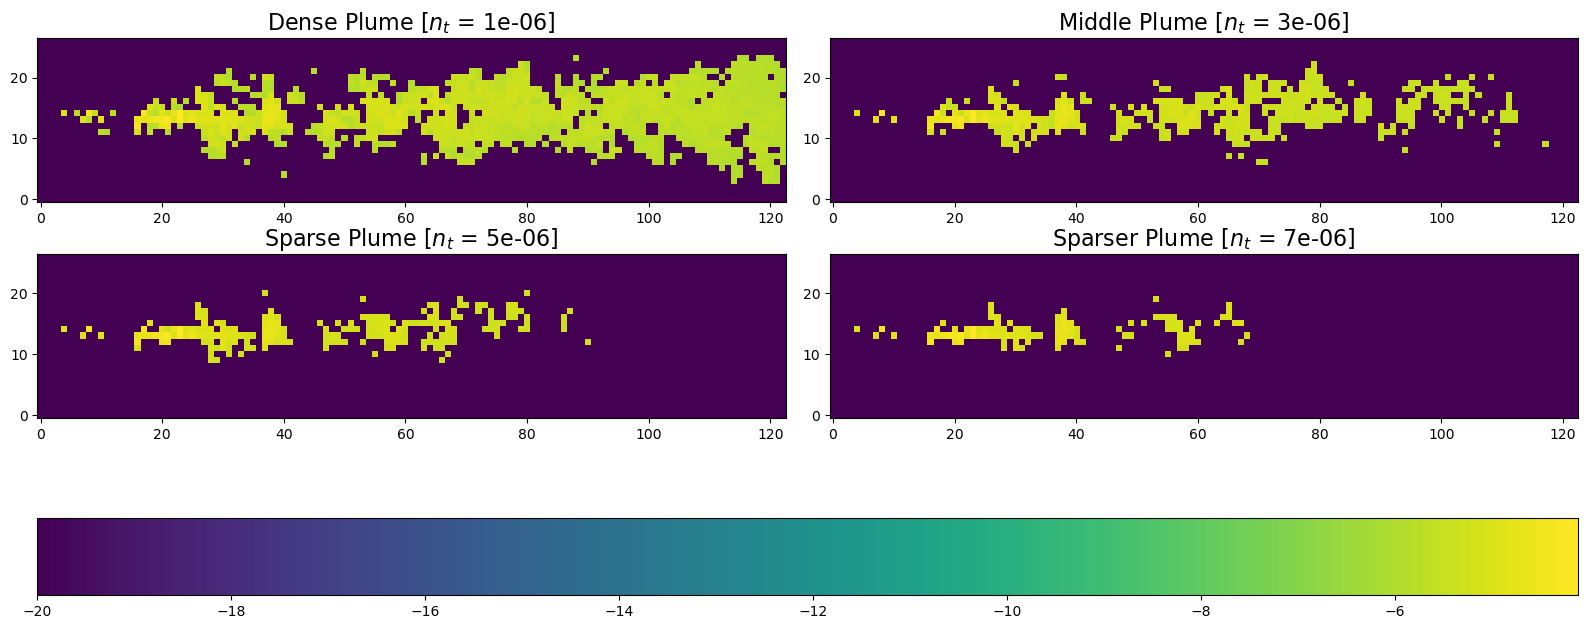

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(16, 7))
#normalizer = Normalize(0, 4)
axes = axes.flatten()
for (i, (n_thr, data)) in enumerate(data_environments.items()):
    axes[i].set_title("{} Plume [$n_t$ = {}]".format(data_labels[i], n_thr), fontsize=16)
    log_data = np.log10(data[100, :, :])
    im = axes[i].imshow(log_data, cmap='viridis', origin='lower', vmax=log_data.max())
    
fig.tight_layout()
fig.colorbar(im, ax=axes.ravel().tolist(), location='bottom')
fig.savefig("./plots/signals.pdf", bbox_inches='tight')


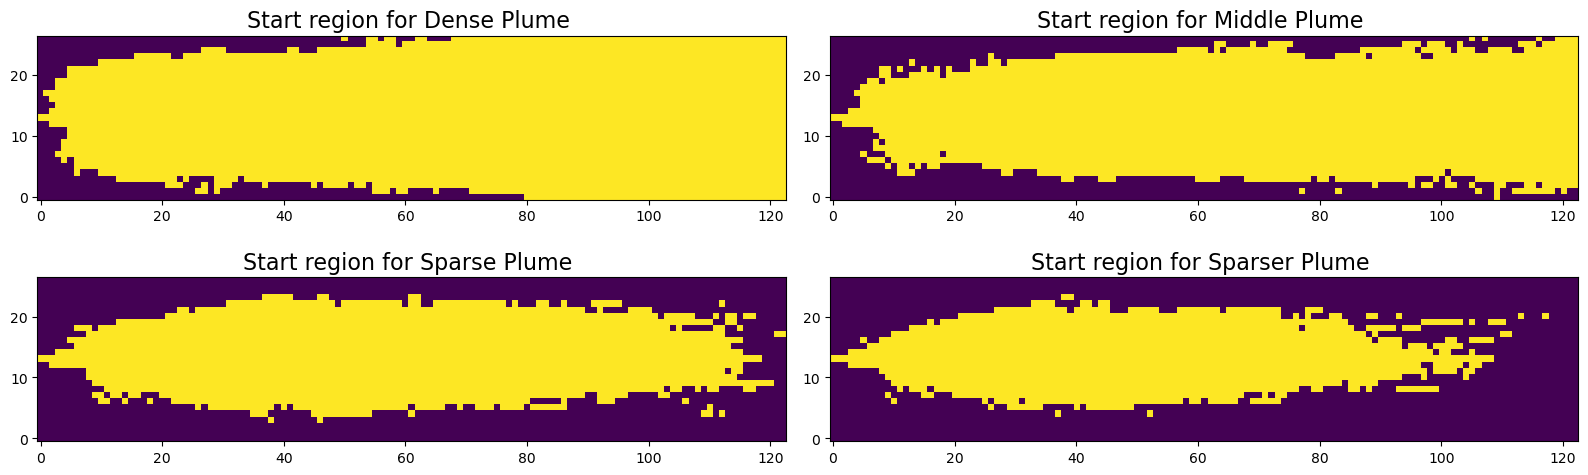

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(16, 5))
axes = axes.flatten()
for (i, (n_thr, data)) in enumerate(start_regions.items()):
    axes[i].set_title("Start region for {} Plume ".format(data_labels[i], n_thr), fontsize=16)
    axes[i].imshow(data, cmap='viridis', origin='lower')
    
fig.tight_layout()
fig.savefig("./plots/start_regions.pdf", bbox_inches='tight')

## Figure 2

In [5]:
out_path = out_paths[2]
agent = QAgent(500)

os.makedirs(out_path, exist_ok=True)

### Figure 2 (a): Structure of a trajectory and examples of dense, middle and sparse trajectories


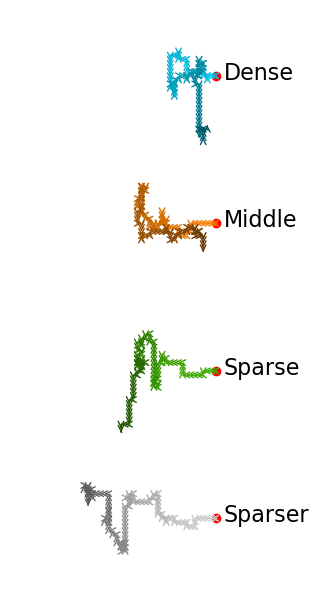

In [6]:


Qs = [
    ('Dense', "/storage/rando/pynav_results_new/single_Q/dense/agent_6299/Q_stored/Qfun.npy", np.array([0x0, 0xcd, 0xf1]) / 0xff ),
    ('Middle', "/storage/rando/pynav_results_new/single_Q/middle/agent_1574/Q_stored/Qfun.npy", np.array([0xfc, 0x81, 0x0]) / 0xff ),
    ('Sparse', "/storage/rando/pynav_results_new/single_Q/sparse/agent_944/Q_stored/Qfun.npy", np.array([0x41, 0xb1, 0x0]) / 0xff),
    ('Sparser', "/storage/rando/pynav_results_new/single_Q/sparser/agent_944/Q_stored/Qfun.npy", np.array([0xd2, 0xd2, 0xd2]) / 0xff),
]

#box_colors = [
#     '#00cdf1',
#     '#fc8100',
#     '#41b100',
#     '#d2d2d2'
# ]

fig, axes = plt.subplots(4, 1, figsize=(12, 6))

for (i, (label, qpath, cmap_str)) in enumerate(Qs):
    agent.load_q(qpath)
    pos = np.array([0, 0])
    ax = axes[i]
    path = [pos.copy()]
    for j in range(1, 500):
        pos += actions[np.argmax(agent.Q[j])]
        path.append(pos.copy())




    ax.plot(path[0][1], path[0][0], 'o', c='red', label='starting point')
#    colormap = cm.get_cmap(box_colors[i])
    plot_steps = 100
    for j in range(plot_steps): 
        ax.plot(path[j][1], path[j][0], '.', ms=1, color= ((170 - (j+1))/170) * cmap_str )
        ax.annotate("", xytext=(path[j][1], path[j][0]), xy=(path[j+1][1], path[j+1][0]), arrowprops=dict(arrowstyle='->', color= ((170 - (j+1))/170) * cmap_str ))

    ax.text(2.0, -1.0, f"{label}", fontsize=16)

    ax.set_xlim([-50, 2.0])
    ax.set_axis_off()
    ax.set_aspect('equal')
    ax.set_ylim([-15, 16.0])
fig.tight_layout()
fig.savefig(f"{out_path}/fig2_a_2.pdf", bbox_inches='tight')

### Figure 2 (supplemental): All policies

In [7]:
Qs = [
    ('Dense',  "/storage/rando/pynav_results_new/single_Q/dense", np.array([0x0, 0xcd, 0xf1]) / 0xff ),
    ('Middle', "/storage/rando/pynav_results_new/single_Q/middle", np.array([0xfc, 0x81, 0x0]) / 0xff ),
    ('Sparse', "/storage/rando/pynav_results_new/single_Q/sparse", np.array([0x41, 0xb1, 0x0]) / 0xff),
    ('Sparser',"/storage/rando/pynav_results_new/single_Q/sparser", np.array([0xd2, 0xd2, 0xd2]) / 0xff),
]


for (label, main_path, color_rgb) in Qs:
    dirs= os.listdir(main_path)
    n_plots = len(dirs) // 5 # + 1
    fig, ax = plt.subplots(n_plots, 5, figsize=(10, 14))


    axes = ax.flatten()
    for i in range(len(dirs)):
        agent.load_q(f"{main_path}/{dirs[i]}/Q_stored/Qfun.npy")
        
        pos = np.array([0, 0])
        ax = axes[i]
        path = [pos.copy()]
        plot_steps = 100
        for j in range(1, plot_steps + 1):
            pos += actions[np.argmax(agent.Q[j])]
            path.append(pos.copy())

        ax.plot(path[0][1], path[0][0], 'o', c='red', label='starting point')
        for j in range(plot_steps): 
            ax.plot(path[j][1], path[j][0], '.', ms=1, color=((170 - (j+1))/170) * color_rgb )
            ax.annotate("", xytext=(path[j][1], path[j][0]), xy=(path[j+1][1], path[j+1][0]), arrowprops=dict(arrowstyle='->', color=((170 - (j+1))/170) * color_rgb))

        ax.set_xlim([-51, 1.0])
        ax.set_axis_off()
        ax.set_aspect('equal')
    
    if len(dirs) < len(axes):
        for i in range(len(axes) - len(dirs)):
            axes[-i-1].set_axis_off()
    fig.tight_layout()
    fig.savefig(f"{out_path}/fig2_supp_1q_policies_{label}.pdf", bbox_inches='tight')
    plt.close(fig)
    print(f"[--] Completed {label}")


[--] Completed Dense
[--] Completed Middle
[--] Completed Sparse
[--] Completed Sparser


In [6]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/single_Q"

tr_max_void = [[], [], [], []]
tr_mean_void = [[], [], [], []]

tr_max_steps = [[], [], [], []]
tr_mean_steps = [[], [], [], []]


tr_max_state =  [[], [], [], []]
tr_mean_state =  [[], [], [], []]

delta = 500

for (i, setting) in enumerate(settings):
    for seed in agent_seeds:
        with open(f"{base_dir}/{setting}/agent_{seed}/training.log", 'r') as f:
            num_void_steps, num_steps = [], []
            for line in f.readlines()[-delta:]:
                num_void_steps.append(int(line.split(',')[-1]))
                num_steps.append(int(line.split(',')[-2]))
            
            tr_max_void[i].append(np.max(num_void_steps))
            tr_mean_void[i].append(np.mean(num_void_steps))
            tr_max_steps[i].append(np.max(num_steps))
            tr_mean_steps[i].append(np.mean(num_steps))


        tr_states = np.load(f"{base_dir}/{setting}/agent_{seed}/training_max_void_lengths.npy")
        tr_max_state[i].append(np.max(tr_states[-delta:]))
        tr_mean_state[i].append(np.mean(tr_states[-delta:]))
#        avg_void = np.mean(max_void[-delta:])
#            for j in range(len(num_vsteps) - delta):
#                avg_tr_vsteps[i].append(np.mean(num_vsteps[j : j + delta]))
        
#        tr_max_void[i].append(avg_void)
    print(f"[--] Completed setting {setting}")



[--] Completed setting dense
[--] Completed setting middle
[--] Completed setting sparse
[--] Completed setting sparser


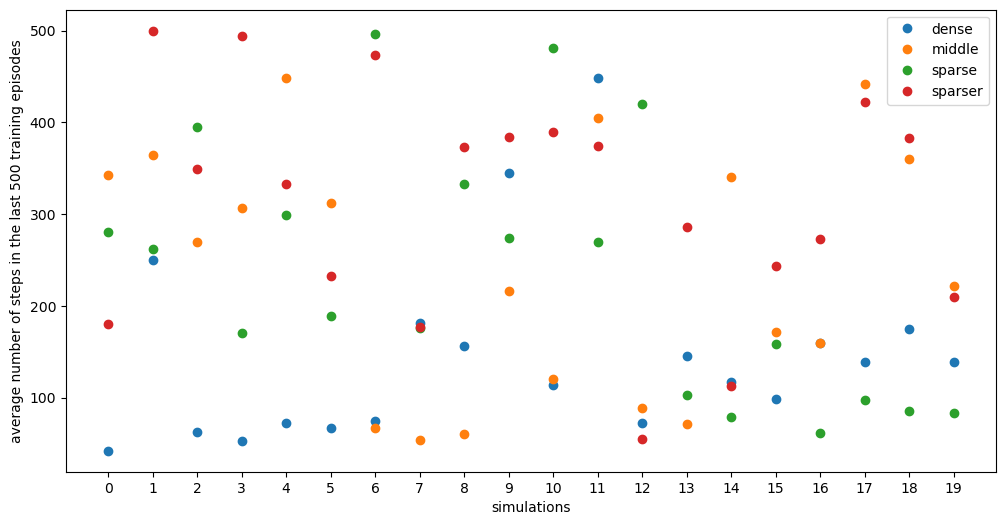

In [7]:
fig, ax = plt.subplots(figsize=(12, 6))
for i in range(len(settings)):
    mu = np.array(tr_max_state[i])
    ax.plot(range(mu.shape[0]), mu, 'o', lw=3, label=settings[i])
#    ax.fill_between(range(mu.shape[0]), np.maximum(mu - std, 0), mu + std, alpha=0.2)
    
ax.set_xticks(range(0, 20))
    
ax.set_xlabel("simulations")
ax.set_ylabel(f"average number of steps in the last {delta} training episodes")
    
ax.legend()

In [9]:
def compute_surge_length(Q_file, num_accepted_steps = 2, count_from = 1, count_to = None):
    agent.load_q(Q_file)
#    print(agent.Q.shape)
    num_left = 0
    num_updown = 0
    count_to = agent.Q.shape[0] if count_to is None else count_to
    for i in range(count_from, count_to):
        if np.argmax(agent.Q[i]) == 3:
            num_left += 1
        if np.argmax(agent.Q[i]) == 0 or np.argmax(agent.Q[i]) ==1:
            num_updown += 1
        else:
            num_updown = 0
        if num_updown >= num_accepted_steps:
            break 
    return max(num_left  - num_accepted_steps, 0)

def compute_backtracking_length(Q_file, avg_void, count_from=1):
    agent.load_q(Q_file)
    pos = np.zeros(2)
    max_pos = (0, 0, pos)
    for i in range(count_from, avg_void+1):
        pos += actions[np.argmax(agent.Q[i])]
        if max_pos[1] > pos[1]:
            max_pos = (i, pos[1], pos)
            
    back_pos = max_pos[2]
    pos = max_pos[2]
    for i in range(max_pos[0], avg_void + 1):
        pos += actions[np.argmax(agent.Q[i])]
        if back_pos[1] < pos[1]:
            back_pos = (i, pos[1], pos)
        
    return abs(back_pos[1] - max_pos[1])


def compute_backtracking_init_time(Q_file, avg_void, acceptance_steps = 2, count_from=1):
    agent.load_q(Q_file)
    pos = np.zeros(2)
    num_right = 0
    for i in range(count_from, avg_void+1):
        if np.argmax(agent.Q[i]) == 2:
            num_right += 1
        elif np.argmax(agent.Q[i]) == 3:
            num_right = 0 
        if num_right > acceptance_steps:
            break
    return max(i - acceptance_steps, 0)


def compute_search_length(Q_file, avg_void, count_from=1):
    agent.load_q(Q_file)
    pos = np.zeros(2)
    max_pos = 0
    for i in range(count_from, avg_void+1):
        pos += actions[np.argmax(agent.Q[i])]
        max_pos = min(pos[1], max_pos)
    return abs(max_pos)

def compute_cast_width(Q_file, avg_void, count_from=1):
    agent.load_q(Q_file)
    max_pos = 0.0
    min_pos = 0.0
    pos = np.zeros(2)
    for i in range(count_from, avg_void +1):
        pos += actions[np.argmax(agent.Q[i])]
        max_pos = max(pos[0], max_pos, 0)
        min_pos = min(pos[0], min_pos, 0)
    return max_pos + abs(min_pos)


metric_names = ["mean_state", "max_state", "mean_void", "max_void", "entire_traj"]
metrics = [tr_mean_state, tr_max_state, tr_mean_void, tr_max_void, 500]



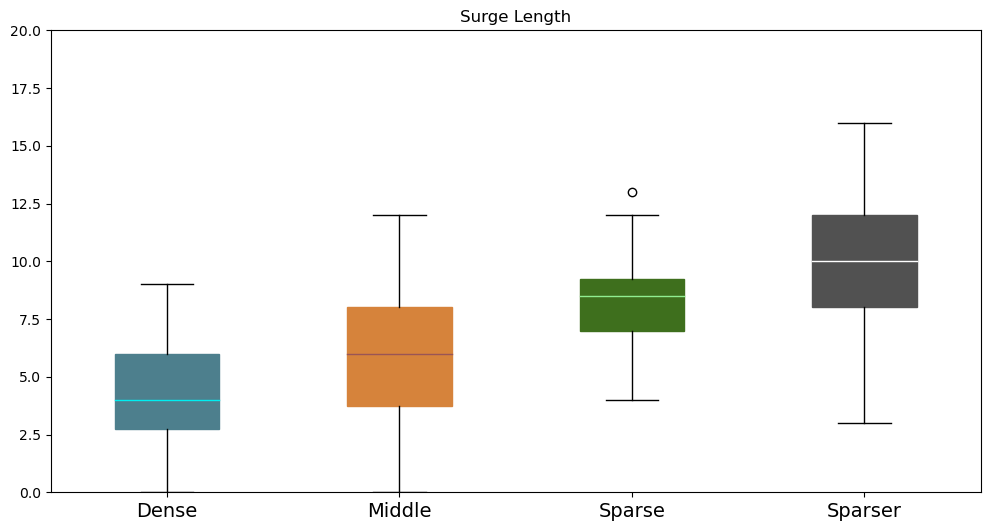

In [15]:


surge_length = [[], [], [], []]

for (i, setting) in enumerate(settings):
    for seed in agent_seeds:
        surge_length[i].append(compute_surge_length(f"{base_dir}/{setting}/agent_{seed}/Q_stored/Qfun.npy", num_accepted_steps=2))


fig, ax = plt.subplots(1, 1, figsize=(12, 6))

b = ax.boxplot(surge_length, patch_artist=True)
for i in range(len(b['boxes'])):
    b['boxes'][i].set_color(box_colors[i])
    b['medians'][i].set_color(median_colors[i])



ax.set_ylim([0, 20])

ax.set_title("Surge Length")
ax.set_xticklabels(data_labels, fontsize=14)
fig.savefig(f"{out_path}/fig2_b.pdf", bbox_inches='tight')



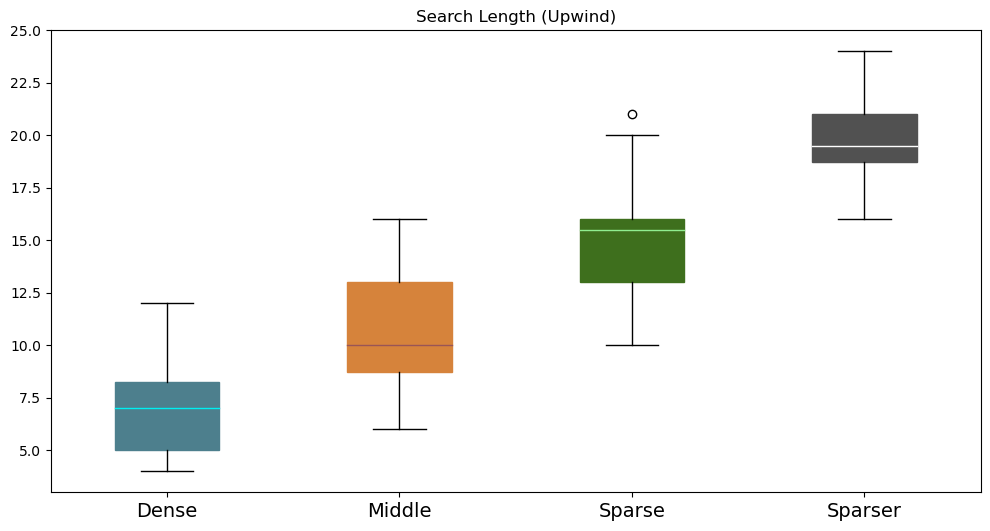

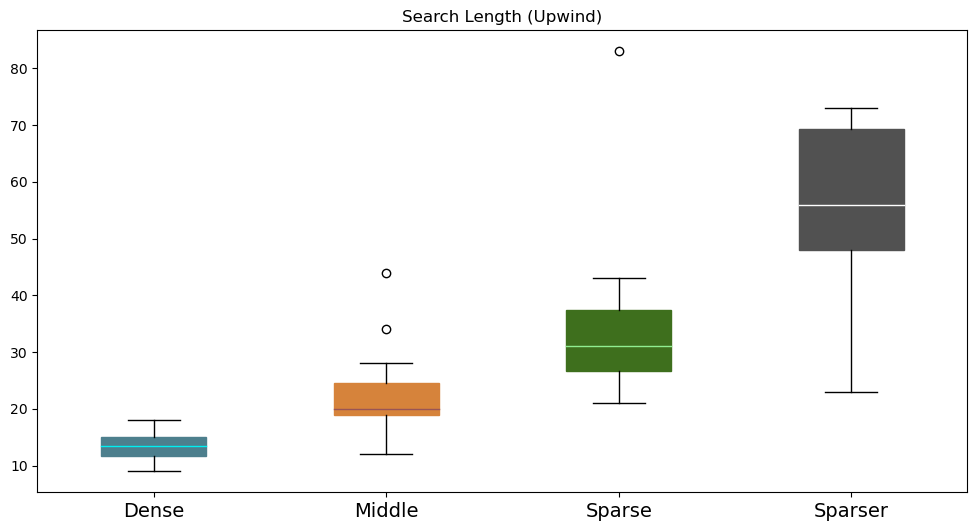

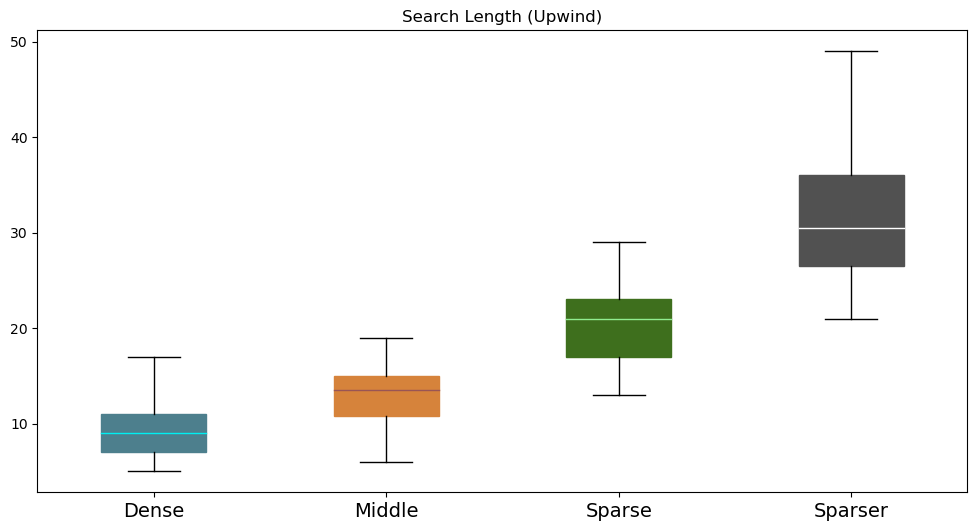

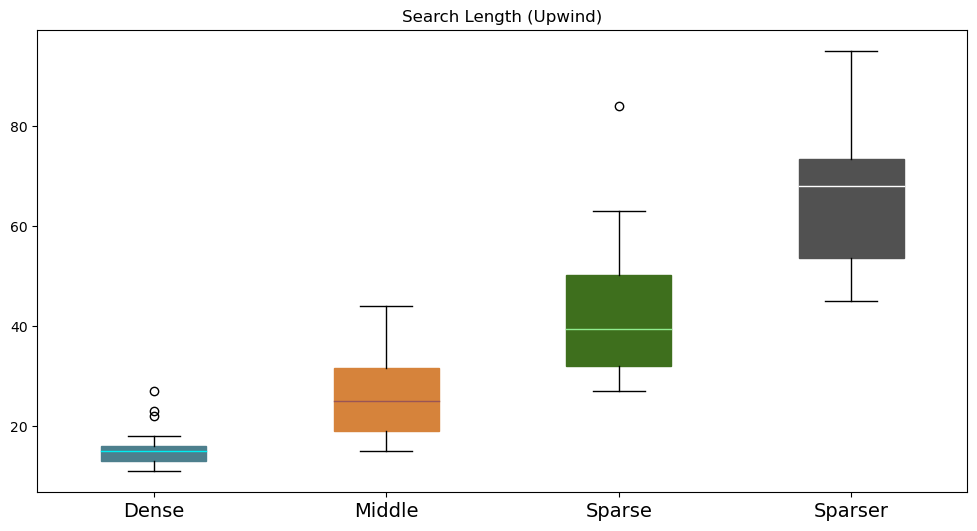

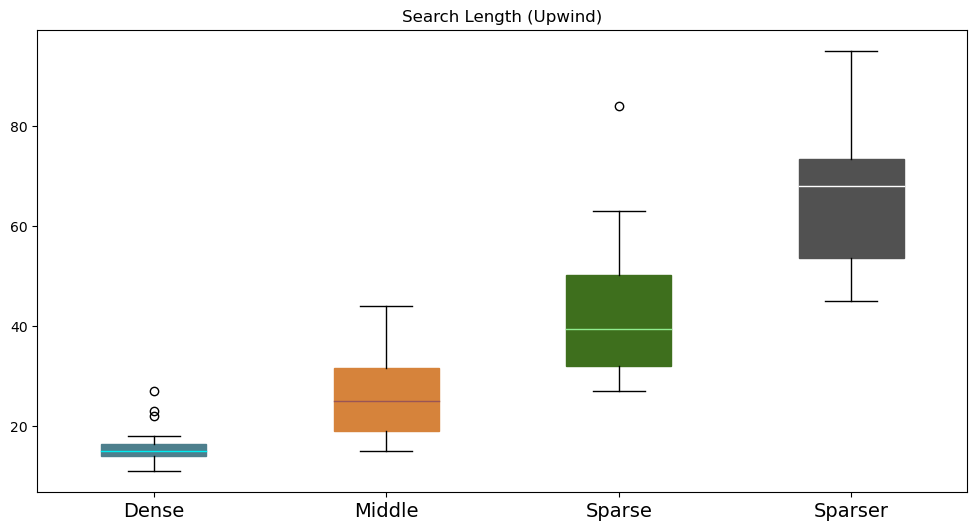

In [16]:

for met,met_name in zip(metrics, metric_names):

	search_len = [[], [], [], []]
	for (i, setting) in enumerate(settings):
			for (j, seed) in enumerate(agent_seeds):
					if met_name == 'entire_traj':
						search_len[i].append(compute_search_length(f"{base_dir}/{setting}/agent_{seed}/Q_stored/Qfun.npy", 500 ) ) 
					else:
						search_len[i].append(compute_search_length(f"{base_dir}/{setting}/agent_{seed}/Q_stored/Qfun.npy", round(met[i][j]) ) ) 


	fig, ax = plt.subplots(1, 1, figsize=(12, 6))

	b = ax.boxplot(search_len, patch_artist=True)
	for i in range(len(b['boxes'])):
			b['boxes'][i].set_color(box_colors[i])
			b['medians'][i].set_color(median_colors[i])

	ax.set_title("Search Length (Upwind)")
	ax.set_xticklabels(data_labels, fontsize=14)

	fig.savefig(f"{out_path}/fig2_c_{met_name}.pdf", bbox_inches='tight')




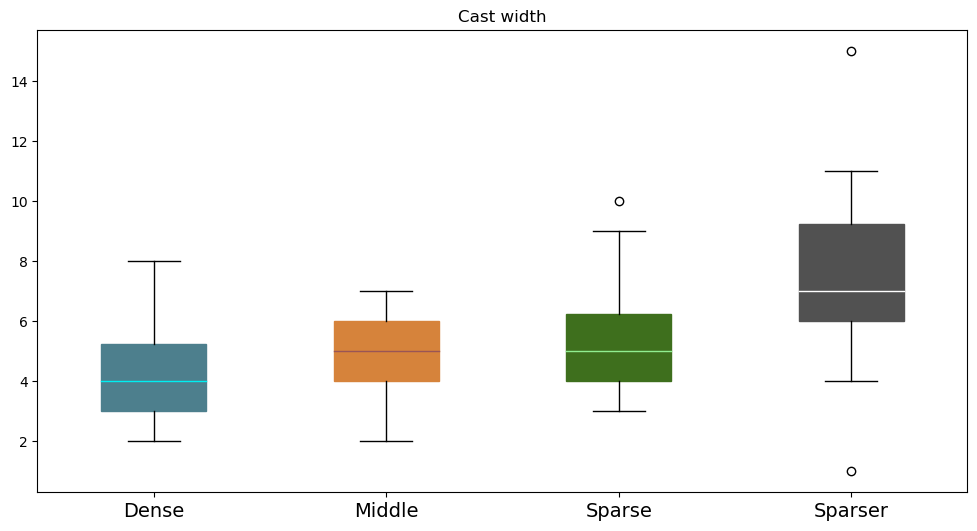

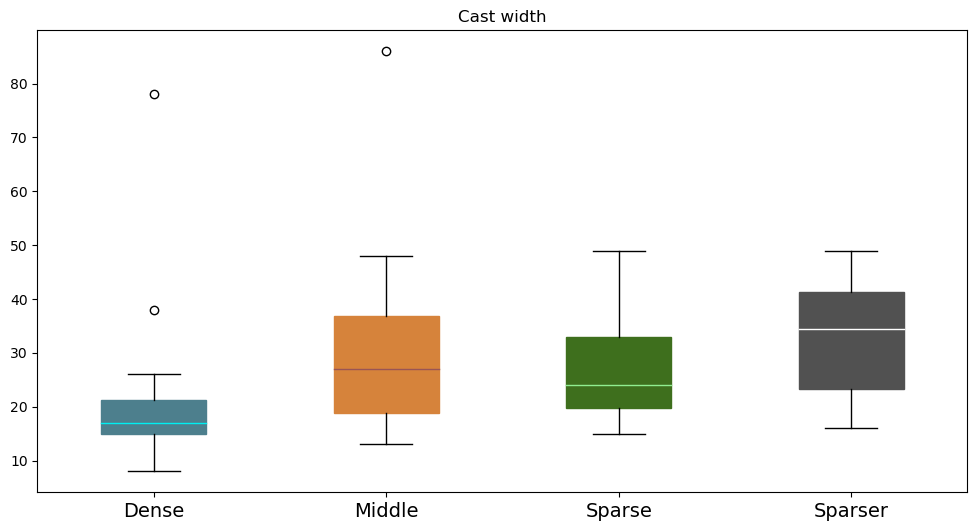

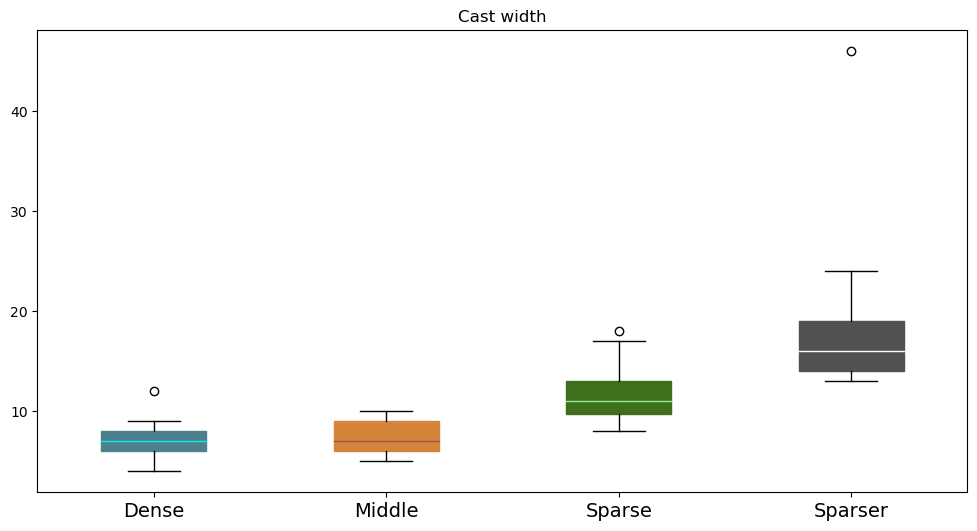

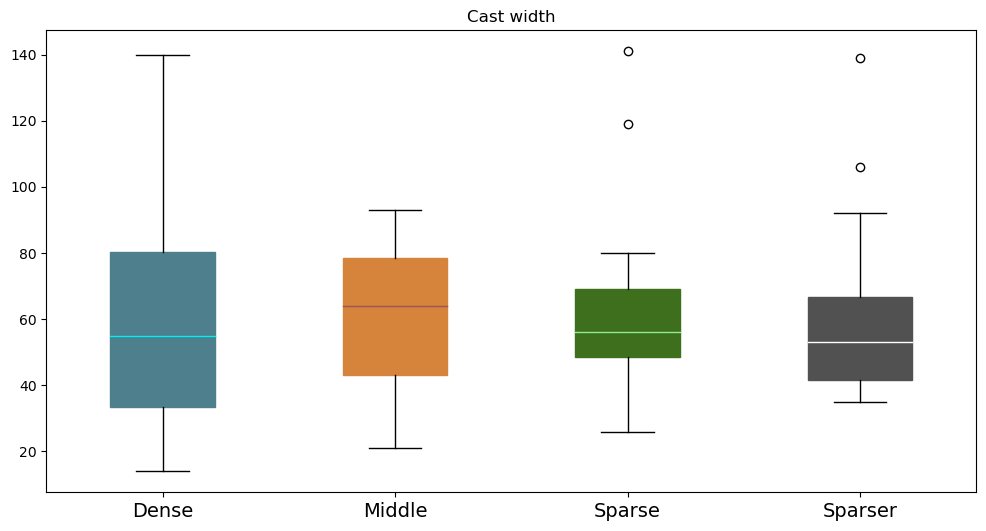

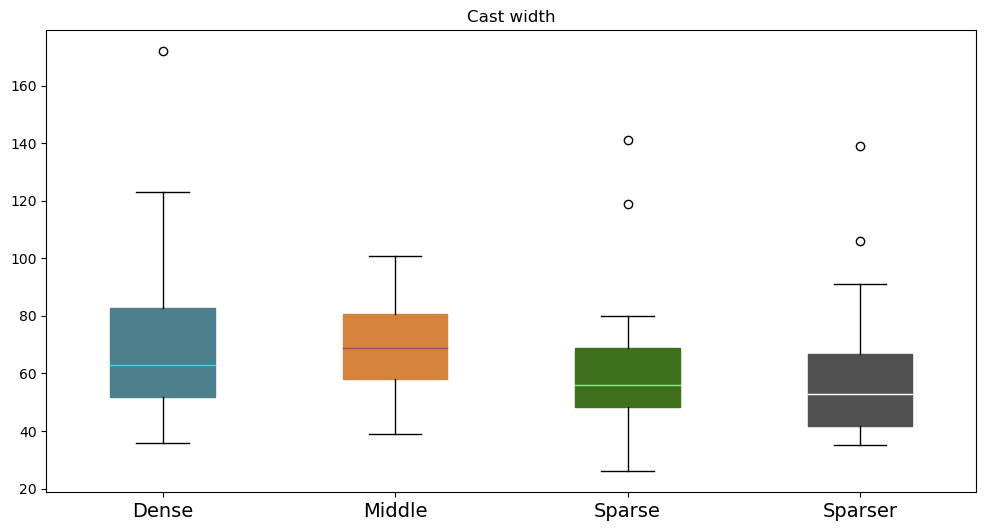

In [17]:



for met,met_name in zip(metrics, metric_names):
	cast_width = [[], [], [], []]

	for (i, setting) in enumerate(settings):
		for (j, seed) in enumerate(agent_seeds):
						if met_name == 'entire_traj':
							cast_width[i].append(compute_cast_width(f"{base_dir}/{setting}/agent_{seed}/Q_stored/Qfun.npy", 500 ) ) 
						else:
							cast_width[i].append(compute_cast_width(f"{base_dir}/{setting}/agent_{seed}/Q_stored/Qfun.npy", round(met[i][j]) ) ) 



	fig, ax = plt.subplots(1, 1, figsize=(12, 6))

	b = ax.boxplot(cast_width, patch_artist=True)

	for i in range(len(b['boxes'])):
		b['boxes'][i].set_color(box_colors[i])
		b['medians'][i].set_color(median_colors[i])


	ax.set_title("Cast width")
	ax.set_xticklabels(data_labels, fontsize=14)
	fig.savefig(f"{out_path}/fig2_d_{met_name}.pdf", bbox_inches='tight')
			




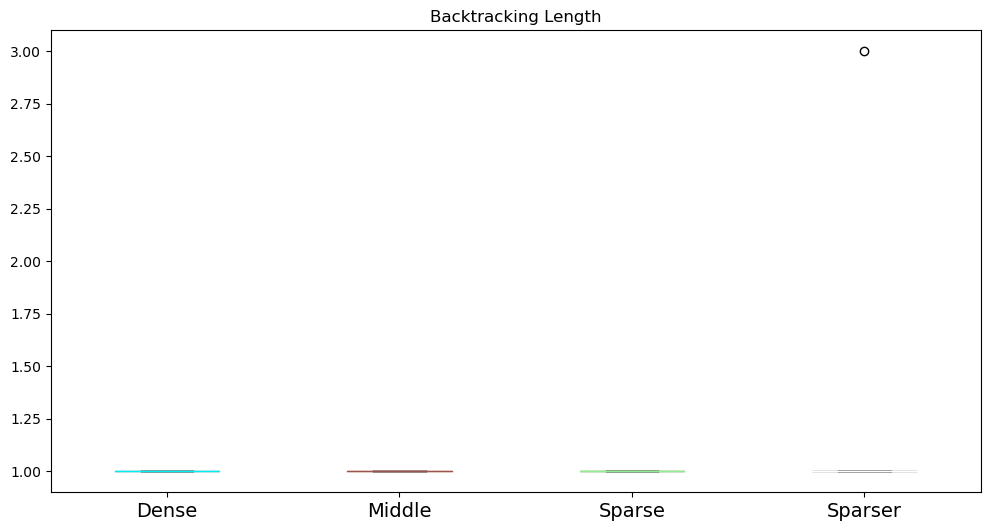

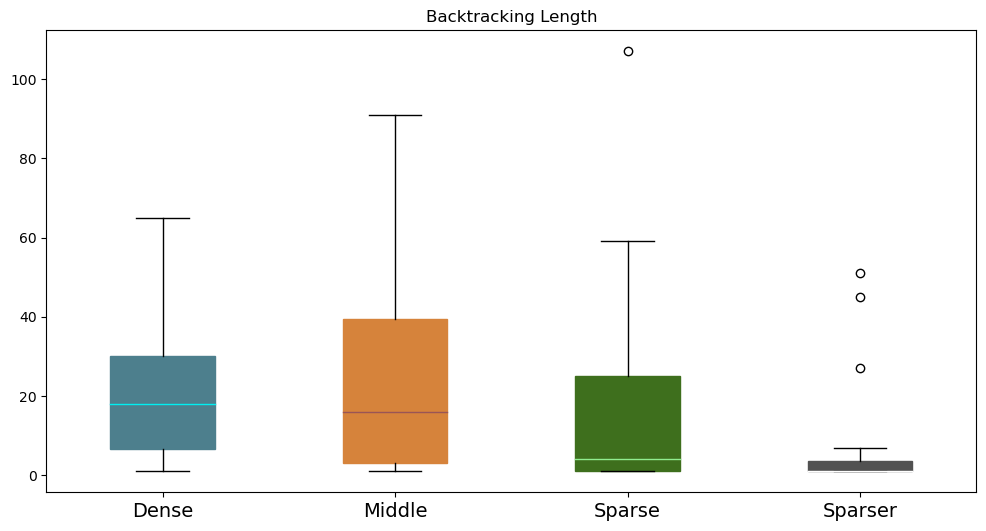

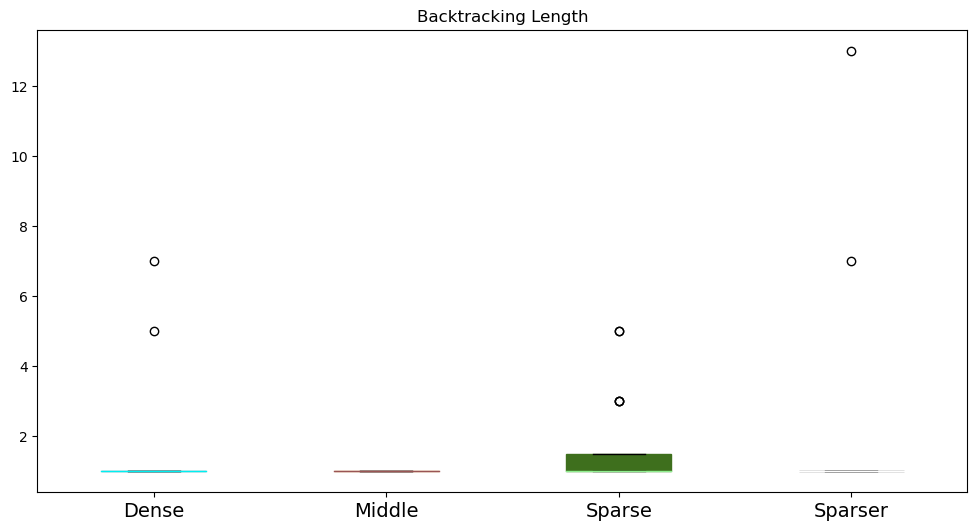

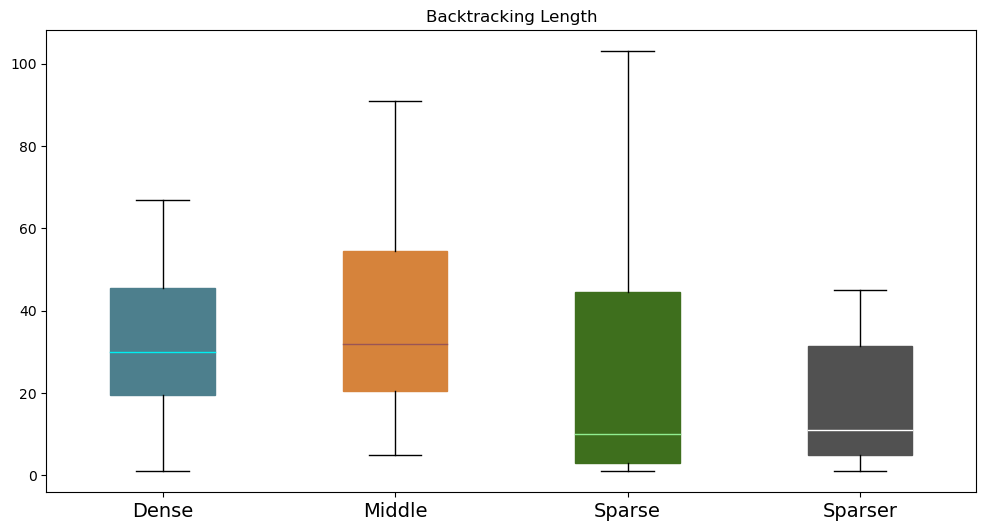

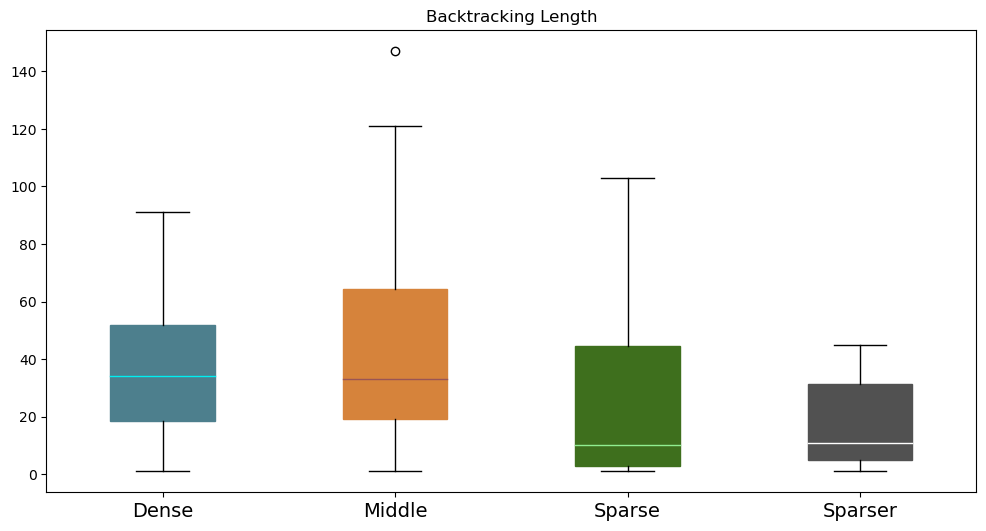

In [18]:

for met,met_name in zip(metrics, metric_names):

	bck_len = [[], [], [], []]

	for (i, setting) in enumerate(settings):
			for (j, seed) in enumerate(agent_seeds):
					if met_name == 'entire_traj':
						bck_len[i].append(compute_backtracking_length(f"{base_dir}/{setting}/agent_{seed}/Q_stored/Qfun.npy", 500 ) ) 
					else:
						bck_len[i].append(compute_backtracking_length(f"{base_dir}/{setting}/agent_{seed}/Q_stored/Qfun.npy", round(met[i][j]) ) ) 


	fig, ax = plt.subplots(1, 1, figsize=(12, 6))

	b = ax.boxplot(bck_len, patch_artist=True)
	for i in range(len(b['boxes'])):
			b['boxes'][i].set_color(box_colors[i])
			b['medians'][i].set_color(median_colors[i])

	ax.set_title("Backtracking Length")
	ax.set_xticklabels(data_labels, fontsize=14)
	fig.savefig(f"{out_path}/fig2_e_{met_name}.pdf", bbox_inches='tight')
#	plt.close(fig)



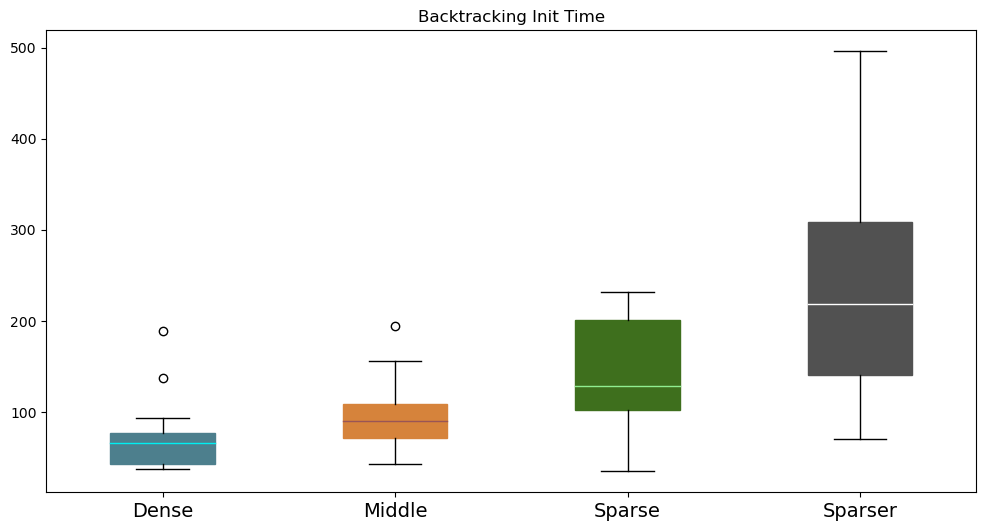

In [19]:



backtrack_init = [[], [], [], []]
acc_steps = 3
for (i, setting) in enumerate(settings):
    for (j, seed) in enumerate(agent_seeds):

        # entire trajectory
        backtrack_init[i].append(compute_backtracking_init_time(f"{base_dir}/{setting}/agent_{seed}/Q_stored/Qfun.npy", 500, acc_steps ))


fig, ax = plt.subplots(1, 1, figsize=(12, 6))

b = ax.boxplot(backtrack_init, patch_artist=True)
for i in range(len(b['boxes'])):
    b['boxes'][i].set_color(box_colors[i])
    b['medians'][i].set_color(median_colors[i])

ax.set_title("Backtracking Init Time")

ax.set_xticklabels(data_labels, fontsize=14)
fig.savefig(f"{out_path}/fig2_f.pdf", bbox_inches='tight')
#plt.close(fig)


In [ ]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/single_Q"

Q_nums = [0, 50000]#, 100000, 500000, 1000000, 1500000, 2000000, 2500000, 3000000]

last_detections = {setting : [[] for _ in range(len(Q_nums))] for setting in settings}


for setting in settings:
    for seed in agent_seeds:
        for i in range(len(Q_nums)):       
            with open(f"{base_dir}/{setting}/agent_{seed}/test/{setting}/Q_{Q_nums[i]}/failed_last_detections.log", 'r') as f:
                last_detections[setting][i] += [float(x.split(',')[1]) for x in f.readlines()]


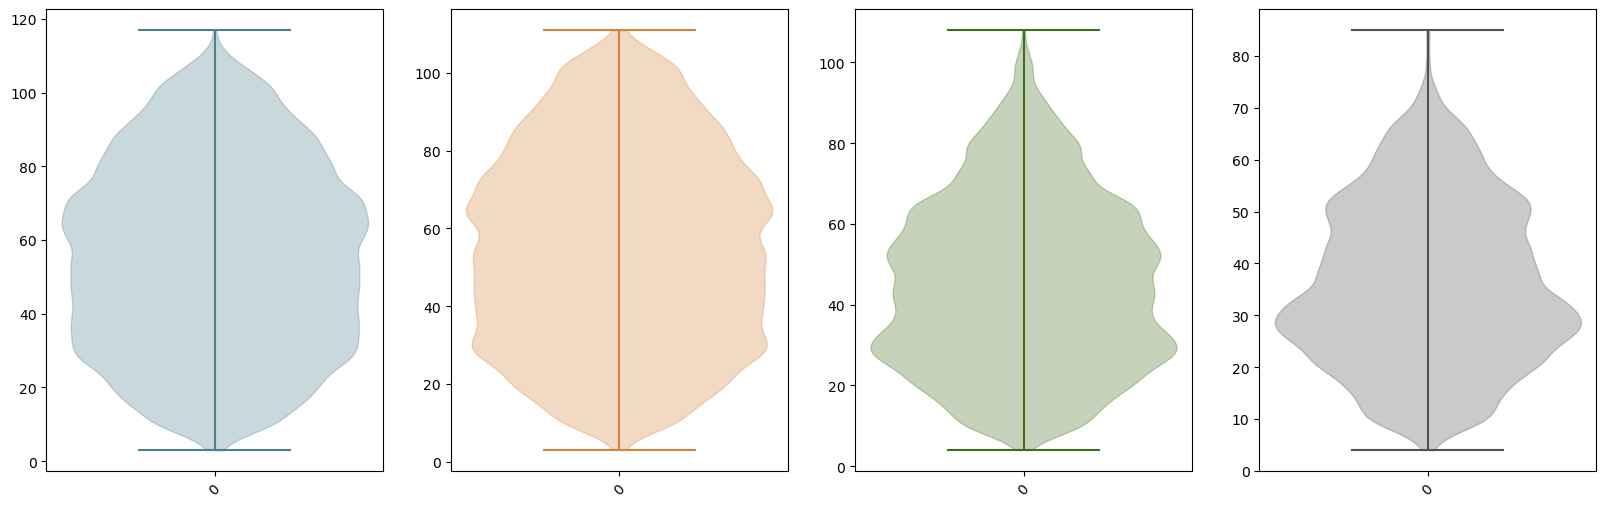

In [10]:



fig, axes = plt.subplots(1, 4, figsize=(20, 6))

for (idx, label) in zip(range(4), data_labels):

    violin = axes[idx].violinplot(last_detections[data_labels[idx].lower()], positions=range(len(Q_nums)) )


    for e in violin['bodies']:
        e.set_facecolor(box_colors[idx])
        e.set_edgecolor(box_colors[idx])

    for lab in ['cbars', 'cmins', 'cmaxes']:
        violin[lab].set_edgecolor(box_colors[idx])
        violin[lab].set_facecolor(box_colors[idx])
        
#    axes[idx].set_ylim([0, 30])
    axes[idx].set_xticks(range(len(Q_nums)), Q_nums, rotation=45)
#fig.savefig(f"{out_path}/fig2_g.pdf", bbox_inches='tight')



In [22]:
data = np.load("/storage/rando/data/nose_data_27_123.npy") # replace with your data path
noise_thresholds = [1e-6, 3e-6, 5e-6, 7e-6]
data_labels = ['Dense', 'Middle', 'Sparse', 'Sparser']

blanks = {}
num_blanks = {}
mean_blank_map = {}

for n_thr in noise_thresholds:
    new_data = data.copy()
    new_data[new_data < n_thr] = 0.0
    blanks[n_thr] = []
    mean_blank_map[n_thr] = np.zeros((data.shape[1], data.shape[2]))
    num_blanks[n_thr] = 0
    print(np.count_nonzero(new_data, axis=0).shape)
    for i in range(new_data.shape[1]):
        for j in range(new_data.shape[2]):
            obs = new_data[:, i, j] > n_thr
            count_zero = 0 
            avg_blank = []
            init_idx = np.argmax(obs)
            for k in range(init_idx + 1, len(obs)):
                if not obs[k]:
                    count_zero +=1
                else:
                    if count_zero > 0:
                        avg_blank.append(count_zero)
                    count_zero = 0
            if len(avg_blank) >0:
              blanks[n_thr] += avg_blank
              num_blanks[n_thr] += len(avg_blank)
              mean_blank_map[n_thr][i, j] = np.mean(avg_blank)


(27, 123)
(27, 123)
(27, 123)
(27, 123)


In [11]:
for n_thr in noise_thresholds:
  print("[++] n_thr = {}\n\t[--] Avg blank: {} +/- {}\n\t[--] 10-th Percentile: {}\t95-th Percentile: {}\n\t[--] min: {}\tmax: {}".format(n_thr, np.mean(blanks[n_thr]), np.std(blanks[n_thr]), np.percentile(blanks[n_thr], q=10), np.percentile(blanks[n_thr], q=95), np.min(blanks[n_thr]), np.max(blanks[n_thr]) ))
#  print("[--] Num blank: {}".format(num_blanks[n_thr]))

mean_blanks = np.array([np.mean(blanks[n_thr]) for n_thr in noise_thresholds])
std_blanks  = np.array([np.std(blanks[n_thr]) for n_thr in noise_thresholds])
p10_blanks = np.array([np.percentile(blanks[n_thr], q=10) for n_thr in noise_thresholds])
p95_blanks  = np.array([np.percentile(blanks[n_thr], q=10) for n_thr in noise_thresholds])


[++] n_thr = 1e-06
	[--] Avg blank: 7.76735137000871 +/- 35.81702944664332
	[--] 10-th Percentile: 1.0	95-th Percentile: 25.0
	[--] min: 1	max: 2391
[++] n_thr = 3e-06
	[--] Avg blank: 10.130460379733345 +/- 40.77479696107458
	[--] 10-th Percentile: 1.0	95-th Percentile: 36.0
	[--] min: 1	max: 2294
[++] n_thr = 5e-06
	[--] Avg blank: 14.036780889541744 +/- 57.4398311063933
	[--] 10-th Percentile: 1.0	95-th Percentile: 50.0
	[--] min: 1	max: 2241
[++] n_thr = 7e-06
	[--] Avg blank: 15.618002129542148 +/- 63.44280576620886
	[--] 10-th Percentile: 1.0	95-th Percentile: 55.0
	[--] min: 1	max: 2272


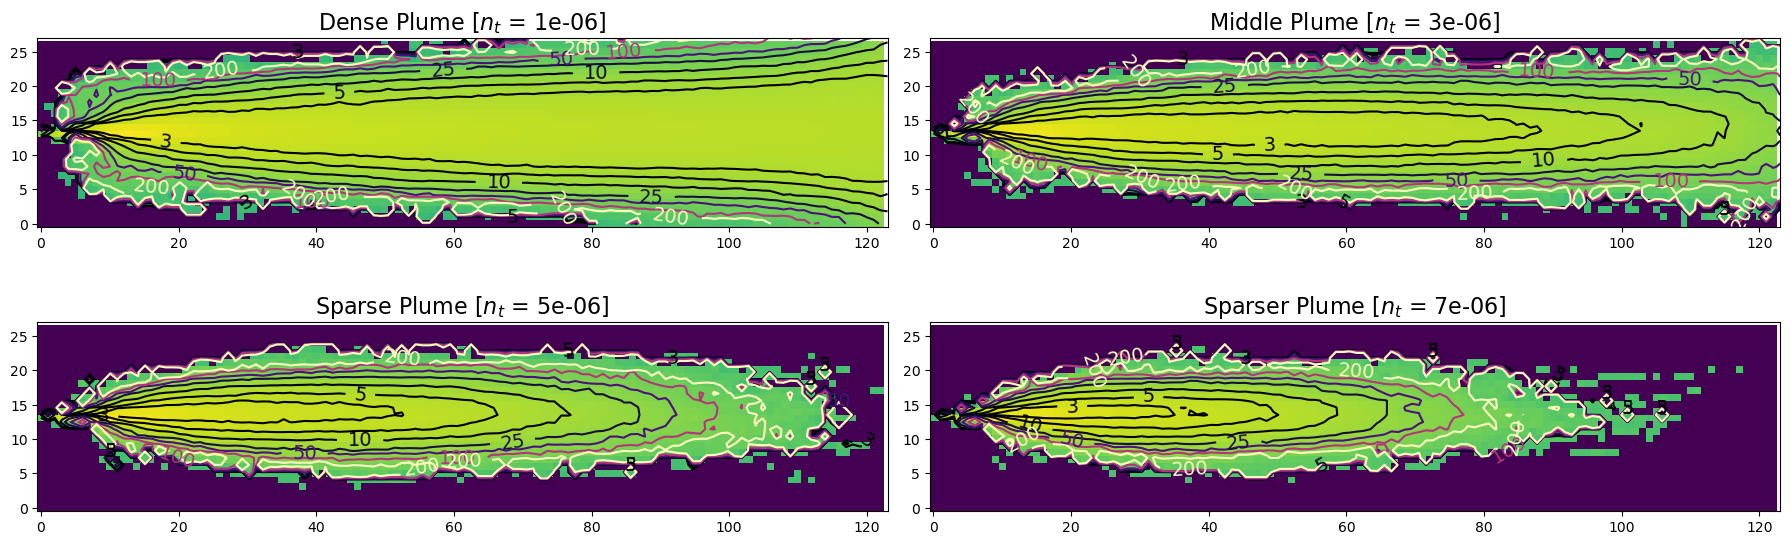

In [23]:
y = np.linspace(0, data.shape[1], data.shape[1])
x = np.linspace(0, data.shape[2], data.shape[2])
X, Y = np.meshgrid(x, y)

fig, axes = plt.subplots(2, 2, figsize=(18, 6))
axes = axes.flatten()
for i in range(len(noise_thresholds)):
  ax = axes[i]
  ax.set_title("{} Plume [$n_t$ = {}]".format(data_labels[i], noise_thresholds[i]), fontsize=16)
  ax.imshow(np.log10(np.mean(data_environments[noise_thresholds[i]], 0)), origin='lower', cmap='viridis')
  contour = ax.contour(X, Y, mean_blank_map[noise_thresholds[i]], levels=[3, 5, 10, 25, 50, 100, 200], cmap='magma')
  ax.clabel(contour, inline=True, fontsize=14)

fig.tight_layout()
#ax.contour(mean_blanks)
fig.savefig("./plots/avg_blanks_contour.pdf", bbox_inches='tight')

In [24]:
mean_blank_map[7e-6][12, 20]

3.5864661654135337

NameError: name 'mean_blanks' is not defined

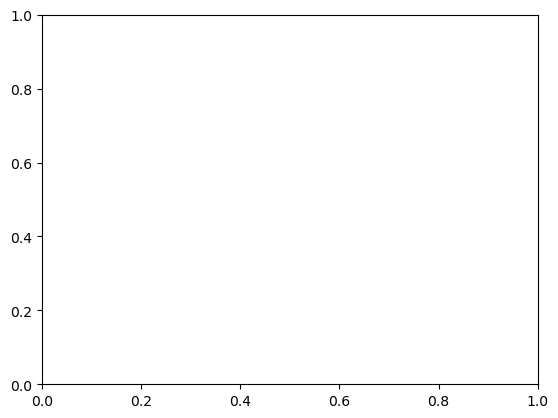

In [25]:
fig, ax = plt.subplots()
#bins = np.concatenate((np.linspace(0, 100, 15), np.linspace(85, 100, 3)))
bins = np.linspace(0, 100, 15)


ax.plot(range(len(mean_blanks)), mean_blanks,'o-', c='black')
ax.fill_between(range(len(std_blanks)), mean_blanks - p10_blanks, mean_blanks + p95_blanks, alpha = 0.4, color='black')

ax.set_xticks(range(len(mean_blanks)), noise_thresholds)
ax.set_xlabel("$n_{thr}$", fontsize=16)
ax.set_ylabel("$<t_b>$", fontsize=16)
ax.legend()


fig.tight_layout()

fig.savefig("./plots/avg_blanks.pdf", bbox_inches='tight')


## Figure 3

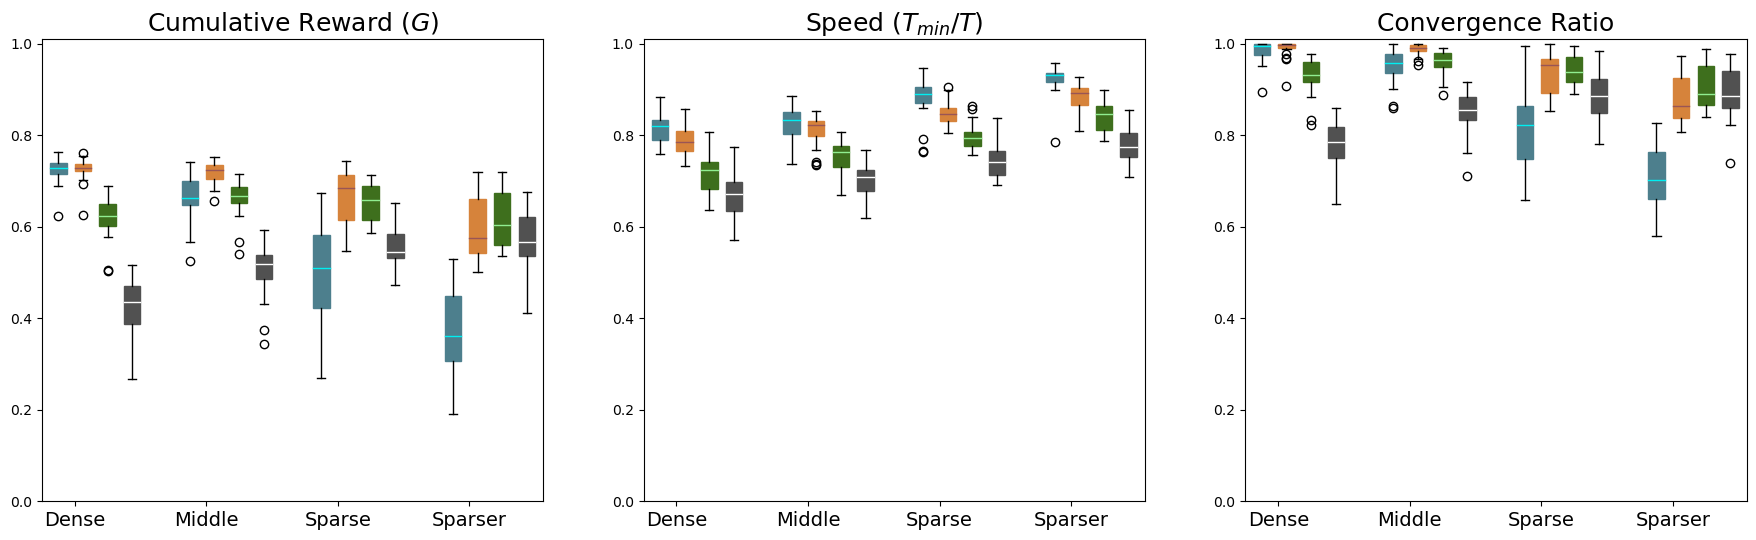

In [4]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/single_Q"

out_path = out_paths[3]
os.makedirs(out_path, exist_ok=True)

creward_data, speed_data, conv_data = [],[],[]
for i in range(len(settings)):
    setting = settings[i] 
    for j in range(len(settings)):
        test_setting = settings[j]
        c_rewards = []
        speeds = []
        convergence = []

        for seed in agent_seeds:
            if not os.path.exists(f"{base_dir}/{setting}/agent_{seed}/test/{test_setting}/test_summary.log"):
              continue
            with open(f"{base_dir}/{setting}/agent_{seed}/test/{test_setting}/test_summary.log", 'r') as f:
                line = f.readline().split(',')
                c_rewards.append(float(line[0]))
                speeds.append(float(line[2]))
                convergence.append(float(line[4]))
        creward_data.append(c_rewards)
        speed_data.append(speeds)
        conv_data.append(convergence)
    

num_settings = 4
num_subgroups = 4
positions = []
group_width = 1.0
subgroup_spacing = 0.75 

for i in range(num_settings):
    base = i * group_width * num_subgroups  
    positions += [base + j * subgroup_spacing for j in range(num_subgroups)]


fig, ax = plt.subplots(1, 3, figsize=(22, 6))
b1 = ax[0].boxplot(creward_data, positions=positions, patch_artist=True)
b2 = ax[1].boxplot(speed_data, positions=positions, patch_artist=True)
b3 = ax[2].boxplot(conv_data, positions=positions, patch_artist=True)


#print(len(b1), b1)

for i in range(len(b1['boxes'])):
    b1['boxes'][i].set_color(box_colors[i % 4])
    b1['medians'][i].set_color(median_colors[i % 4])
    b2['boxes'][i].set_color(box_colors[i % 4])
    b2['medians'][i].set_color(median_colors[i % 4])
    b3['boxes'][i].set_color(box_colors[i % 4])
    b3['medians'][i].set_color(median_colors[i % 4])

xticks = [(i * group_width * num_subgroups) + (group_width / 2) for i in range(num_settings)]
for i in range(len(ax)):
    ax[i].set_xticks(ticks=xticks, labels=data_labels, fontsize=14)

ax[0].set_title("Cumulative Reward ($G$)", fontsize=18)
ax[1].set_title("Speed ($T_{min}/T$)", fontsize=18)
ax[2].set_title("Convergence Ratio", fontsize=18)


ax[0].set_ylim([0.0, 1.01])
ax[1].set_ylim([0.0, 1.01])
ax[2].set_ylim([0.0, 1.01])

fig.savefig(f"{out_path}/fig3_a.pdf", bbox_inches='tight')


## Two-Q

In [13]:
agent = TwoQAgent(horizon=500)
out_path = out_paths[4]
os.makedirs(out_path, exist_ok=True)

tau = 50

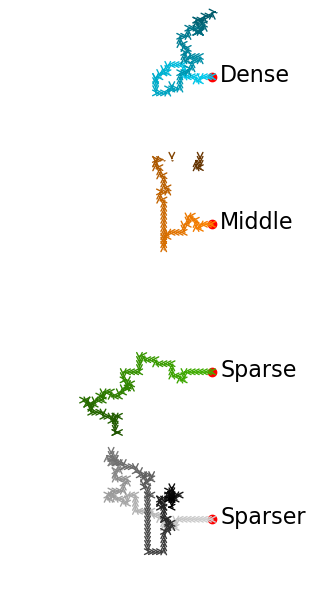

In [14]:


Qs = [
    ('Dense',   f"/storage/rando/pynav_results_new/two_Q/dense/agent_6299/tau_{tau}/Q_stored/Qfun.npy", np.array([0x0, 0xcd, 0xf1]) / 0xff ),
    ('Middle',  f"/storage/rando/pynav_results_new/two_Q/middle/agent_1574/tau_{tau}/Q_stored/Qfun.npy", np.array([0xfc, 0x81, 0x0]) / 0xff ),
    ('Sparse',  f"/storage/rando/pynav_results_new/two_Q/sparse/agent_5354/tau_{tau}/Q_stored/Qfun.npy", np.array([0x41, 0xb1, 0x0]) / 0xff),
    ('Sparser', f"/storage/rando/pynav_results_new/two_Q/sparser/agent_944/tau_{tau}/Q_stored/Qfun.npy", np.array([0xd2, 0xd2, 0xd2]) / 0xff),
    # ('Dense', "/storage/rando/pynav_results_new/two_Q/dense/agent_6299/tau_50/Q_stored/Qfun_2000000.npy", np.array([0x0, 0xcd, 0xf1]) / 0xff ),
    # ('Middle', "/storage/rando/pynav_results_new/two_Q/middle/agent_1574/tau_50/Q_stored/Qfun_2000000.npy", np.array([0xfc, 0x81, 0x0]) / 0xff ),
    # ('Sparse', "/storage/rando/pynav_results_new/two_Q/sparse/agent_5354/tau_50/Q_stored/Qfun_2000000.npy", np.array([0x41, 0xb1, 0x0]) / 0xff),
    # ('Sparser', "/storage/rando/pynav_results_new/two_Q/sparser/agent_944/tau_50/Q_stored/Qfun_2000000.npy", np.array([0xd2, 0xd2, 0xd2]) / 0xff),

]

fig, axes = plt.subplots(4, 1, figsize=(12, 6))

for (i, (label, qpath, cmap_str)) in enumerate(Qs):
    agent.load_q(qpath)
    pos = np.array([0, 0])
    ax = axes[i]
    path = [pos.copy()]
    for j in range(1, 500):
        pos += actions[np.argmax(agent.Q[j])]
        path.append(pos.copy())




    ax.plot(path[0][1], path[0][0], 'o', c='red', label='starting point')
#    colormap = cm.get_cmap(box_colors[i])
    plot_steps = 170
    for j in range(plot_steps): 
        ax.plot(path[j][1], path[j][0], '.', ms=1, color= ((170 - (j+1))/170) * cmap_str )
        ax.annotate("", xytext=(path[j][1], path[j][0]), xy=(path[j+1][1], path[j+1][0]), arrowprops=dict(arrowstyle='->', color= ((170 - (j+1))/170) * cmap_str ))

    ax.text(2.0, -1.0, f"{label}", fontsize=16)

    ax.set_xlim([-50, 2.0])
    ax.set_axis_off()
    ax.set_aspect('equal')
    ax.set_ylim([-15, 16.0])
fig.tight_layout()
fig.savefig(f"{out_path}/fig4_a_1_q1.pdf", bbox_inches='tight')

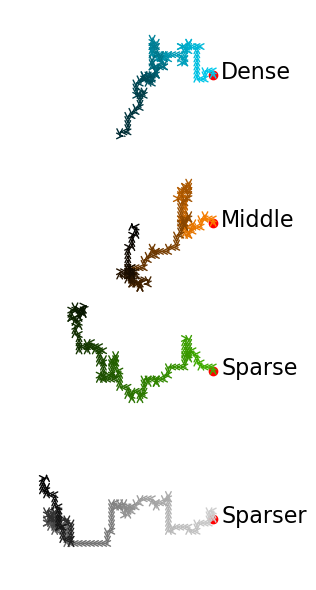

In [15]:


Qs = [
    ('Dense',   f"/storage/rando/pynav_results_new/two_Q/dense/agent_6299/tau_{tau}/Q_stored/Qfun.npy", np.array([0x0, 0xcd, 0xf1]) / 0xff ),
    ('Middle',  f"/storage/rando/pynav_results_new/two_Q/middle/agent_1574/tau_{tau}/Q_stored/Qfun.npy", np.array([0xfc, 0x81, 0x0]) / 0xff ),
    ('Sparse',  f"/storage/rando/pynav_results_new/two_Q/sparse/agent_5354/tau_{tau}/Q_stored/Qfun.npy", np.array([0x41, 0xb1, 0x0]) / 0xff),
    ('Sparser', f"/storage/rando/pynav_results_new/two_Q/sparser/agent_944/tau_{tau}/Q_stored/Qfun.npy", np.array([0xd2, 0xd2, 0xd2]) / 0xff),
    # ('Dense', "/storage/rando/pynav_results_new/two_Q/dense/agent_6299/tau_50/Q_stored/Qfun_2000000.npy", np.array([0x0, 0xcd, 0xf1]) / 0xff ),
    # ('Middle', "/storage/rando/pynav_results_new/two_Q/middle/agent_1574/tau_50/Q_stored/Qfun_2000000.npy", np.array([0xfc, 0x81, 0x0]) / 0xff ),
    # ('Sparse', "/storage/rando/pynav_results_new/two_Q/sparse/agent_5354/tau_50/Q_stored/Qfun_2000000.npy", np.array([0x41, 0xb1, 0x0]) / 0xff),
    # ('Sparser', "/storage/rando/pynav_results_new/two_Q/sparser/agent_944/tau_50/Q_stored/Qfun_2000000.npy", np.array([0xd2, 0xd2, 0xd2]) / 0xff),
]

fig, axes = plt.subplots(4, 1, figsize=(12, 6))

for (i, (label, qpath, cmap_str)) in enumerate(Qs):
    agent.load_q(qpath)
    pos = np.array([0, 0])
    ax = axes[i]
    path = [pos.copy()]
    for j in range(502, 1004):
        pos += actions[np.argmax(agent.Q[j])]
        path.append(pos.copy())




    ax.plot(path[0][1], path[0][0], 'o', c='red', label='starting point')
#    colormap = cm.get_cmap(box_colors[i])
    plot_steps = 170
    for j in range(plot_steps): 
        ax.plot(path[j][1], path[j][0], '.', ms=1, color= ((170 - (j+1))/170) * cmap_str )
        ax.annotate("", xytext=(path[j][1], path[j][0]), xy=(path[j+1][1], path[j+1][0]), arrowprops=dict(arrowstyle='->', color= ((170 - (j+1))/170) * cmap_str ))

    ax.text(2.0, -1.0, f"{label}", fontsize=16)

    ax.set_xlim([-50, 2.0])
    ax.set_axis_off()
    ax.set_aspect('equal')
    ax.set_ylim([-15, 16.0])
fig.tight_layout()

fig.savefig(f"{out_path}/fig4_a_1_q2.pdf", bbox_inches='tight')

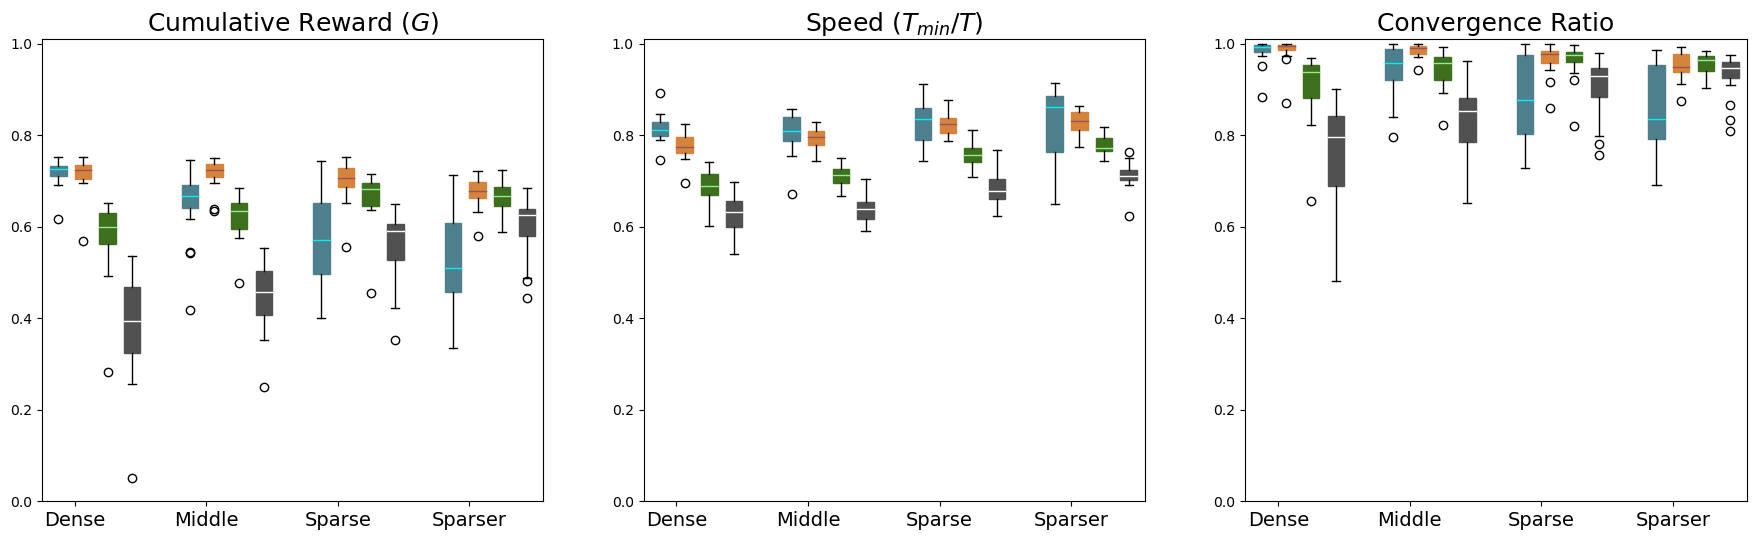

In [16]:

agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/two_Q"



creward_data, speed_data, conv_data = [],[],[]
for i in range(len(settings)):
    setting = settings[i] 
    for j in range(len(settings)):
        test_setting = settings[j]
        c_rewards = []
        speeds = []
        convergence = []

        for seed in agent_seeds:
            if not os.path.exists(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/test/{test_setting}/test_summary.log"):
              continue

            with open(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/test/{test_setting}/test_summary.log", 'r') as f:
                line = f.readline().split(',')
                c_rewards.append(float(line[0]))
                speeds.append(float(line[2]))
                convergence.append(float(line[4]))
        creward_data.append(c_rewards)
        speed_data.append(speeds)
        conv_data.append(convergence)
    

num_settings = 4
num_subgroups = 4
positions = []
group_width = 1.0
subgroup_spacing = 0.75 

for i in range(num_settings):
    base = i * group_width * num_subgroups  
    positions += [base + j * subgroup_spacing for j in range(num_subgroups)]


fig, ax = plt.subplots(1, 3, figsize=(22, 6))
b1 = ax[0].boxplot(creward_data, positions=positions, patch_artist=True)
b2 = ax[1].boxplot(speed_data, positions=positions, patch_artist=True)
b3 = ax[2].boxplot(conv_data, positions=positions, patch_artist=True)


#print(len(b1), b1)

for i in range(len(b1['boxes'])):
    b1['boxes'][i].set_color(box_colors[i % 4])
    b1['medians'][i].set_color(median_colors[i % 4])
    b2['boxes'][i].set_color(box_colors[i % 4])
    b2['medians'][i].set_color(median_colors[i % 4])
    b3['boxes'][i].set_color(box_colors[i % 4])
    b3['medians'][i].set_color(median_colors[i % 4])

xticks = [(i * group_width * num_subgroups) + (group_width / 2) for i in range(num_settings)]
for i in range(len(ax)):
    ax[i].set_xticks(ticks=xticks, labels=data_labels, fontsize=14)

ax[0].set_title("Cumulative Reward ($G$)", fontsize=18)
ax[1].set_title("Speed ($T_{min}/T$)", fontsize=18)
ax[2].set_title("Convergence Ratio", fontsize=18)

ax[0].set_ylim([0.0, 1.01])
ax[1].set_ylim([0.0, 1.01])
ax[2].set_ylim([0.0, 1.01])

fig.savefig(f"./performance_twoQ_{tau}.pdf", bbox_inches='tight')



dense 950
middle 849
sparse 1009
sparser 1055


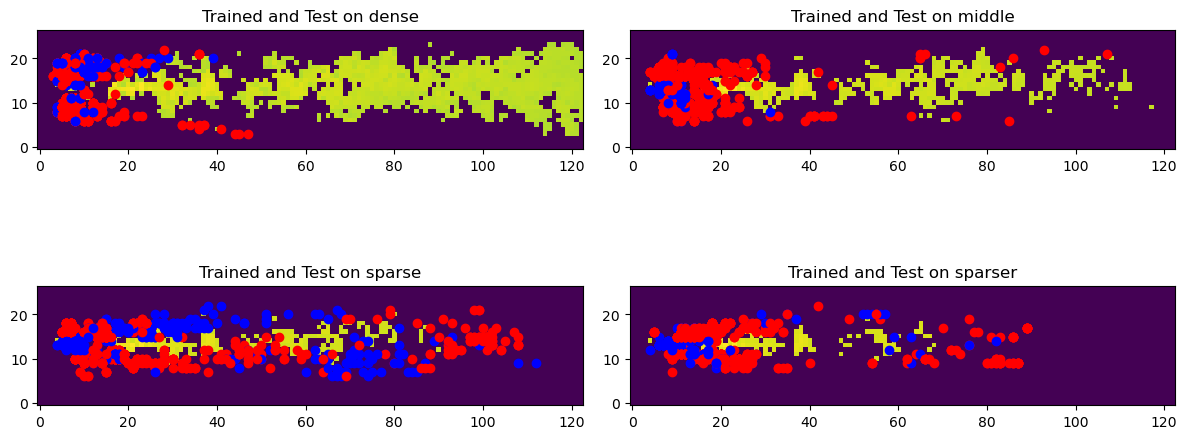

In [17]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/two_Q"


creward_data, speed_data, conv_data = [],[],[]
fig, axes = plt.subplots(2,2, figsize=(12, 6))
axes = axes.flatten()
for i in range(len(settings)):
    ax = axes[i]
    setting = settings[i] 
    x_pos, y_pos = [], []
    Q_num = []
    for seed in agent_seeds:
        with open(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/test/{setting}/failed_last_detections.log", 'r') as f:
            for line in f.readlines():
                splitted = line.split(',')
                y_pos.append(int(splitted[0]))
                x_pos.append(int(splitted[1]))
                Q_num.append(int(splitted[2]))
    new_data = data_environments[noise_thresholds[i]]
    print(setting, len(y_pos))
    ax.set_title(f"Trained and Test on {setting}")
    ax.imshow(np.log10(new_data[100, :, :]), origin='lower')
    for j in range(len(y_pos)):
        if Q_num[j] == 0:
            ax.plot(x_pos[j], y_pos[j], 'o', c='red')
        else:        
            ax.plot(x_pos[j], y_pos[j], 'o', c='blue')
fig.tight_layout()
fig.savefig(f"./last_dection_q_{tau}.pdf", bbox_inches='tight')

IndexError: tuple index out of range

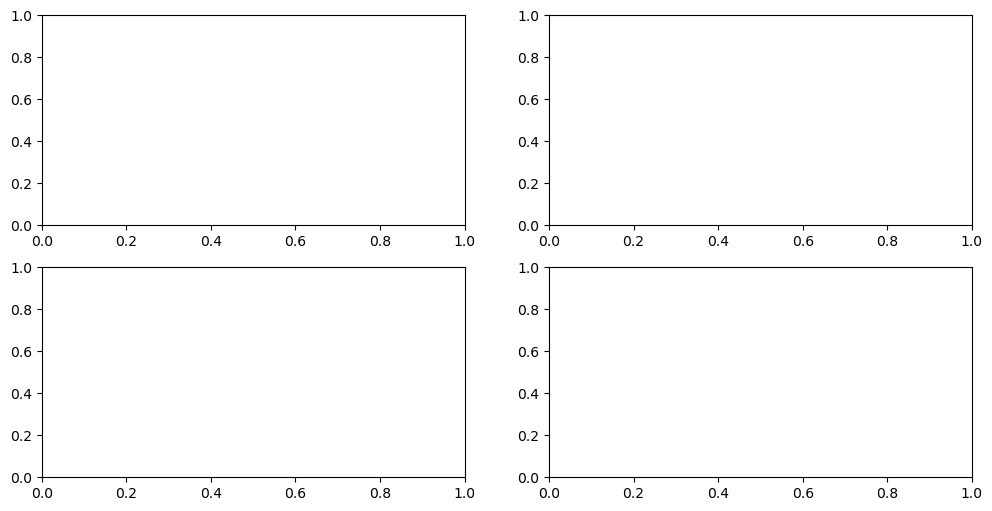

In [6]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/two_Q"



creward_data, speed_data, conv_data = [],[],[]
fig, axes = plt.subplots(2,2, figsize=(12, 6))
axes = axes.flatten()
for i in range(len(settings)):
    ax = axes[i]
    setting = settings[i] 
    Q_v = {}
    Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)
    for seed in agent_seeds:
        with open(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/test/{setting}/Q_used_map.log", 'r') as f:
            for line in f.readlines():
                splitted = line.split(',')
                
                y_pos = int(splitted[0])
                x_pos = int(splitted[1])
                if y_pos not in Q_v:
                    Q_v[y_pos] = {}
                if x_pos not in Q_v[y_pos]:
                    Q_v[y_pos][x_pos] = []
                Q_v[y_pos][x_pos].append(float(splitted[2]))
    for y_pos, xmap in Q_v.items():
        for x_pos, vals in xmap.items():
            Q_map[y_pos, x_pos] = np.mean(vals)

    new_data = data_environments[noise_thresholds[i]]
    ax.set_title(f"Trained and Test on {setting}")
    im =ax.imshow(Q_map, origin='lower', vmin=0.0, vmax=1.0)
    fig.colorbar(im, ax=ax)
#    ax.imshow(np.log10(new_data[100, :, :]), origin='lower')
    # for j in range(len(y_pos)):
    #     if Q_num[j] == 0:
    #         ax.plot(x_pos[j], y_pos[j], 'o', c='red')
    #     else:        
    #         ax.plot(x_pos[j], y_pos[j], 'o', c='blue')
fig.tight_layout()
fig.savefig(f"./two_q_usage_{tau}.pdf", bbox_inches='tight')

## Changing tau

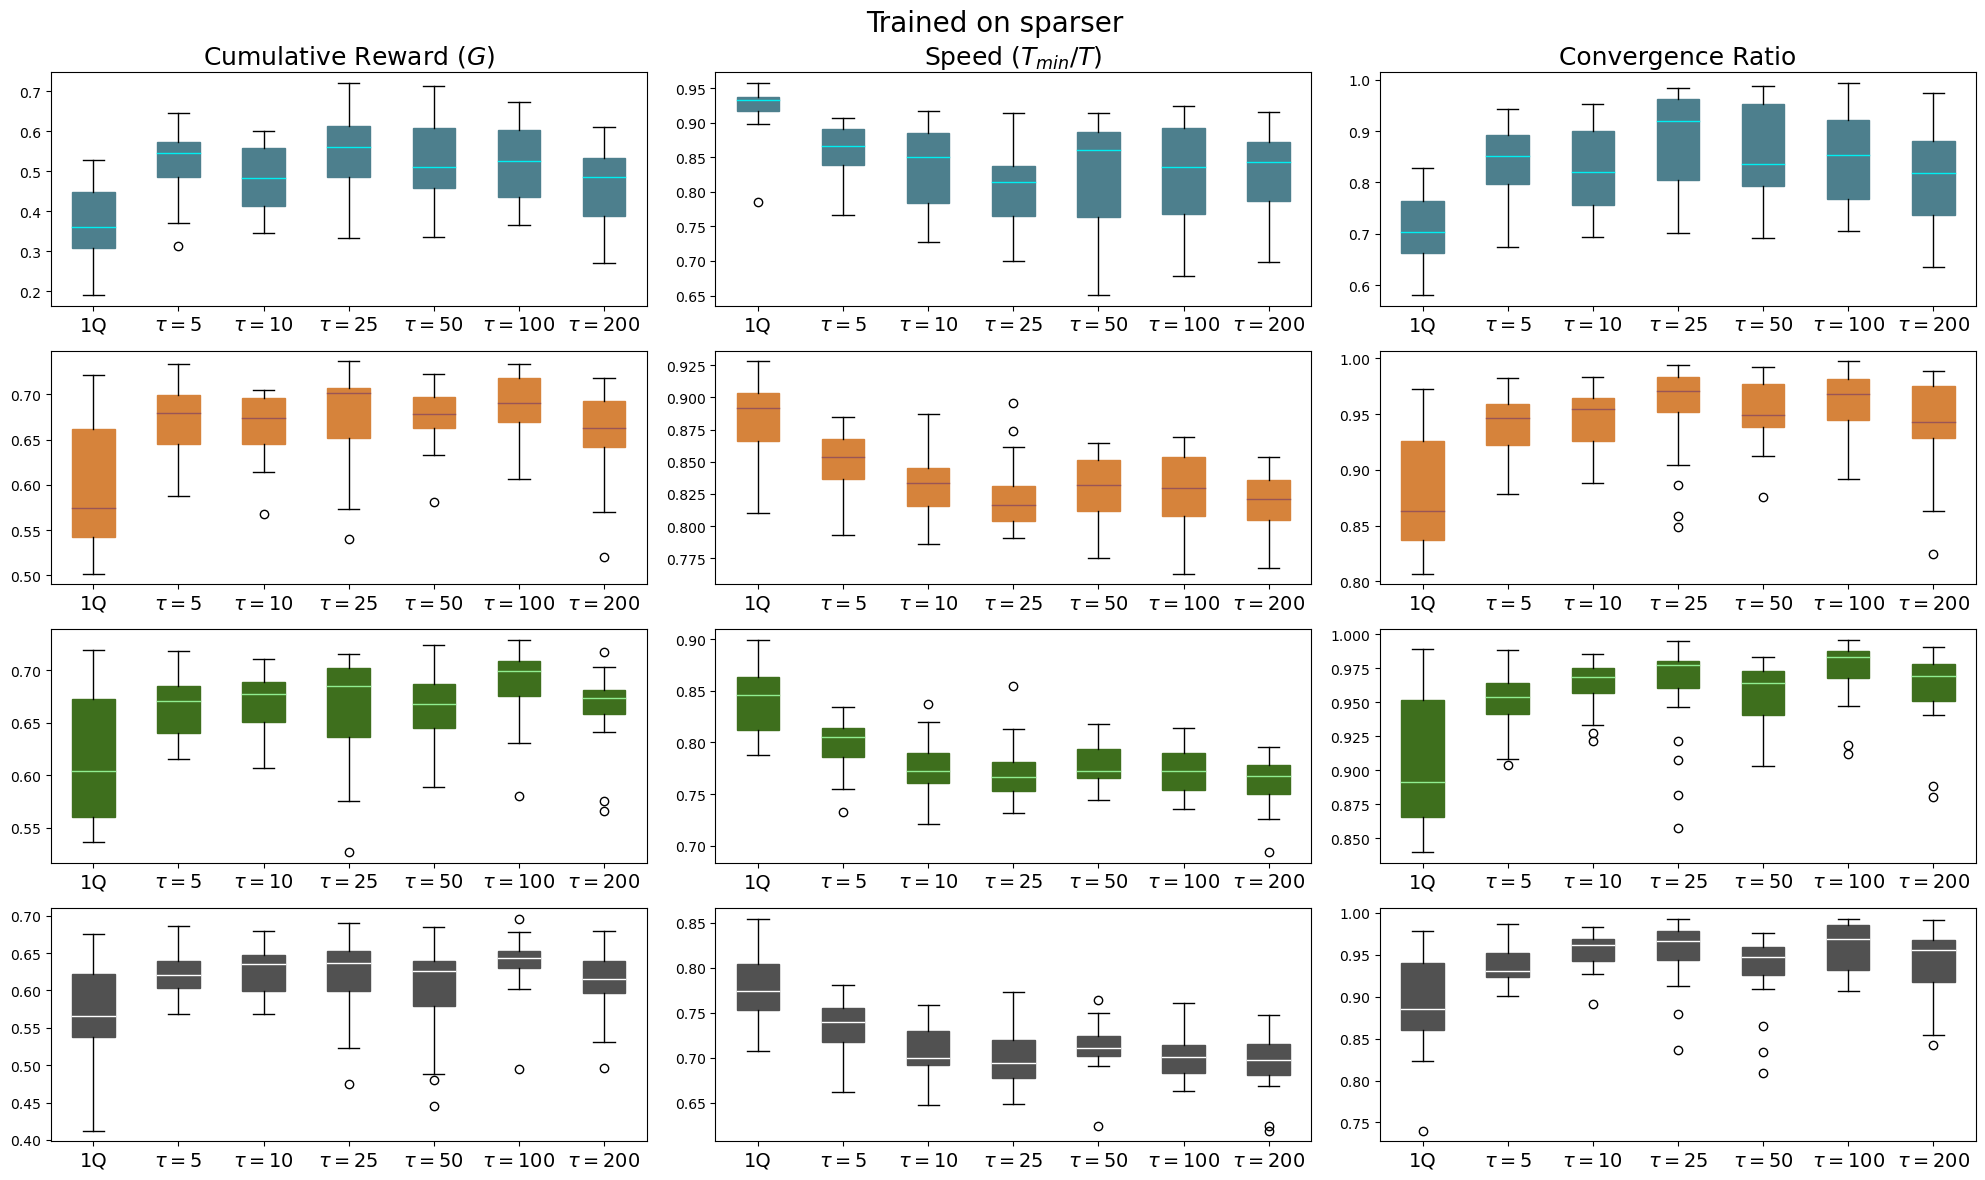

In [10]:
base_dir = "/storage/rando/pynav_results_new"

setting = 'sparser'
taus = [5, 10, 25, 50, 100, 200]
fig, axes = plt.subplots(4, 3, figsize=(20, 12))
for setting_idx, test_setting in enumerate(['dense', 'middle', 'sparse', 'sparser']):
  ax = axes[setting_idx]
  creward_data, speed_data, conv_data = [],[],[]
  c_rewards = []
  speeds = []
  convergence = []

  tick_labels = ['1Q'] + [f'$\\tau = {tau}$' for tau in taus]

  for seed in agent_seeds:
    with open(f"{base_dir}/single_Q/{setting}/agent_{seed}/test/{test_setting}/test_summary.log", 'r') as f:
      splitted = f.readline().split(',')
      c_rewards.append(float(splitted[0]))
      speeds.append(float(splitted[2]))
      convergence.append(float(splitted[4]))

  creward_data.append(c_rewards)
  speed_data.append(speeds)
  conv_data.append(convergence)

  for tau in taus:
    c_rewards = []
    speeds = []
    convergence = []
    for seed in agent_seeds:
      with open(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{tau}/test/{test_setting}/test_summary.log", 'r') as f:
        splitted = f.readline().split(',')
        c_rewards.append(float(splitted[0]))
        speeds.append(float(splitted[2]))
        convergence.append(float(splitted[4]))

    creward_data.append(c_rewards)
    speed_data.append(speeds)
    conv_data.append(convergence)


  # num_settings = 4
  # num_subgroups = 4
  # positions = []
  # group_width = 1.0
  # subgroup_spacing = 0.75 

  # for i in range(num_settings):
  #     base = i * group_width * num_subgroups  
  #     positions += [base + j * subgroup_spacing for j in range(num_subgroups)]


  fig.suptitle(f"Trained on {setting}", fontsize=20)
  b1 = ax[0].boxplot(creward_data,  patch_artist=True)
  b2 = ax[1].boxplot(speed_data,  patch_artist=True)
  b3 = ax[2].boxplot(conv_data,  patch_artist=True)


  #print(len(b1), b1)

  for i in range(len(b1['boxes'])):
      b1['boxes'][i].set_color(box_colors[setting_idx])
      b1['medians'][i].set_color(median_colors[setting_idx])
      b2['boxes'][i].set_color(box_colors[setting_idx])
      b2['medians'][i].set_color(median_colors[setting_idx])
      b3['boxes'][i].set_color(box_colors[setting_idx])
      b3['medians'][i].set_color(median_colors[setting_idx])

  # xticks = [(i * group_width * num_subgroups) + (group_width / 2) for i in range(num_settings)]
  for i in range(len(ax)):
      ax[i].set_xticks(ticks=range(1, len(taus) + 2), labels=tick_labels, fontsize=14)

  if setting_idx == 0:
    ax[0].set_title("Cumulative Reward ($G$)", fontsize=18)
    ax[1].set_title("Speed ($T_{min}/T$)", fontsize=18)
    ax[2].set_title("Convergence Ratio", fontsize=18)
#  ax[0].set_yscale('log')
  # ax[0].set_ylim([0.0, 1.01])
  # ax[1].set_ylim([0.0, 1.01])
  # ax[2].set_ylim([0.0, 1.01])

fig.tight_layout()
fig.savefig(f"./tau_comparison_{setting}.pdf", bbox_inches='tight')



## Characterization

In [39]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/two_Q"
tau = 10
tr_max_void = [[], [], [], []]
tr_mean_void = [[], [], [], []]

tr_max_steps = [[], [], [], []]
tr_mean_steps = [[], [], [], []]


tr_max_state =  [[], [], [], []]
tr_mean_state =  [[], [], [], []]

delta = 500

for (i, setting) in enumerate(settings):
    for seed in agent_seeds:
        with open(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/training.log", 'r') as f:
            num_void_steps, num_steps = [], []
            for line in f.readlines()[-delta:]:
                num_void_steps.append(int(line.split(',')[-1]))
                num_steps.append(int(line.split(',')[-2]))
            
            tr_max_void[i].append(np.max(num_void_steps))
            tr_mean_void[i].append(np.mean(num_void_steps))
            tr_max_steps[i].append(np.max(num_steps))
            tr_mean_steps[i].append(np.mean(num_steps))


        tr_states = np.load(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/training_max_void_lengths.npy")
        tr_max_state[i].append(np.max(tr_states[-delta:]))
        tr_mean_state[i].append(np.mean(tr_states[-delta:]))
#        avg_void = np.mean(max_void[-delta:])
#            for j in range(len(num_vsteps) - delta):
#                avg_tr_vsteps[i].append(np.mean(num_vsteps[j : j + delta]))
        
#        tr_max_void[i].append(avg_void)
    print(f"[--] Completed setting {setting}")



[--] Completed setting dense
[--] Completed setting middle
[--] Completed setting sparse
[--] Completed setting sparser


### Surge Length

[Text(1, 0, 'Dense'),
 Text(2, 0, 'Middle'),
 Text(3, 0, 'Sparse'),
 Text(4, 0, 'Sparser')]

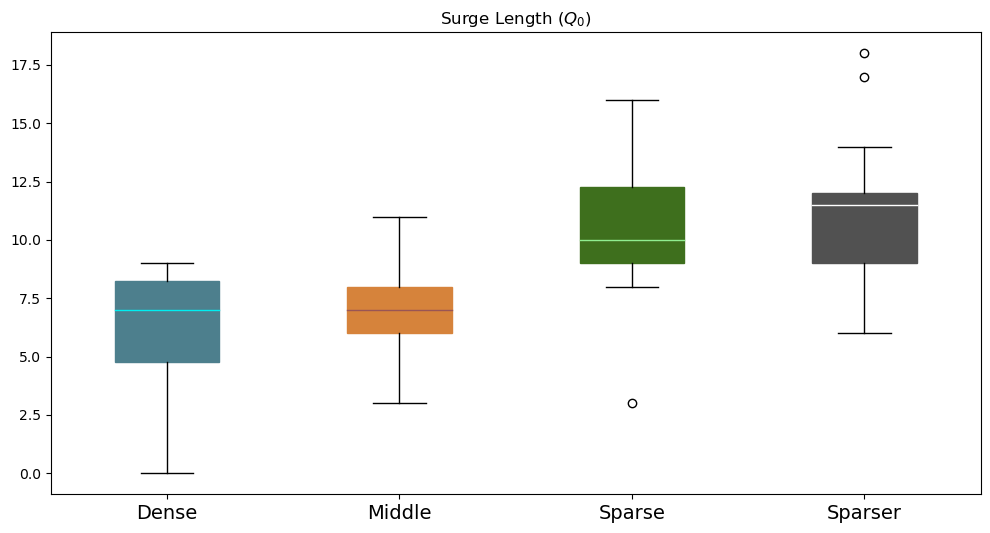

In [40]:


surge_length = [[], [], [], []]

for (i, setting) in enumerate(settings):
    for seed in agent_seeds:
        surge_length[i].append(compute_surge_length(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/Q_stored/Qfun.npy", num_accepted_steps=2, count_from=0, count_to=502))


fig, ax = plt.subplots(1, 1, figsize=(12, 6))

b = ax.boxplot(surge_length, patch_artist=True)
for i in range(len(b['boxes'])):
    b['boxes'][i].set_color(box_colors[i])
    b['medians'][i].set_color(median_colors[i])



#ax.set_ylim([0, 20])

ax.set_title("Surge Length ($Q_0$)")
ax.set_xticklabels(data_labels, fontsize=14)
#fig.savefig(f"{out_path}/fig2_b.pdf", bbox_inches='tight')



[Text(1, 0, 'Dense'),
 Text(2, 0, 'Middle'),
 Text(3, 0, 'Sparse'),
 Text(4, 0, 'Sparser')]

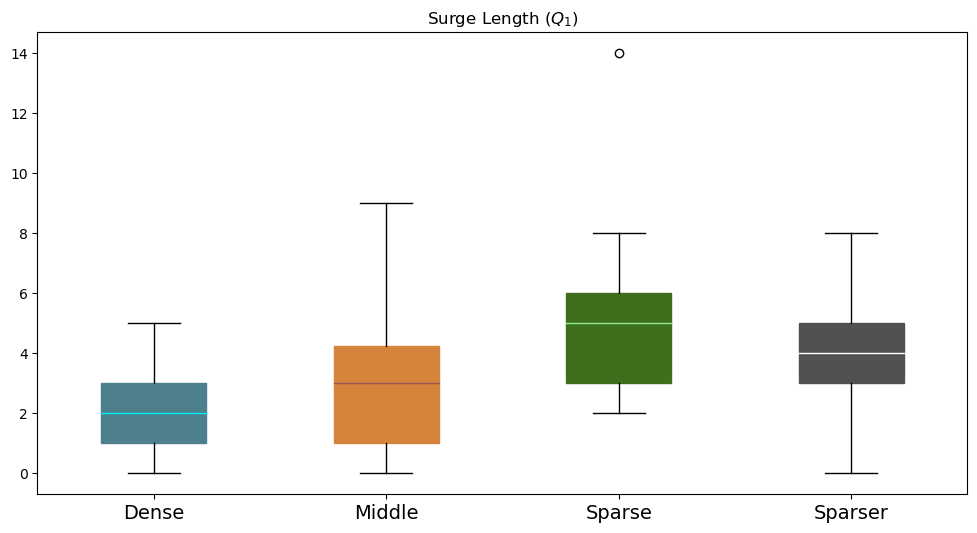

In [42]:


surge_length = [[], [], [], []]

for (i, setting) in enumerate(settings):
    for seed in agent_seeds:
        surge_length[i].append(compute_surge_length(f"{base_dir}/{setting}/agent_{seed}/tau_5/Q_stored/Qfun.npy", num_accepted_steps=2, count_from=502, count_to=1004))


fig, ax = plt.subplots(1, 1, figsize=(12, 6))

b = ax.boxplot(surge_length, patch_artist=True)
for i in range(len(b['boxes'])):
    b['boxes'][i].set_color(box_colors[i])
    b['medians'][i].set_color(median_colors[i])



#ax.set_ylim([0, 20])

ax.set_title("Surge Length ($Q_1$)")
ax.set_xticklabels(data_labels, fontsize=14)
#fig.savefig(f"{out_path}/fig2_b.pdf", bbox_inches='tight')



## Search Length

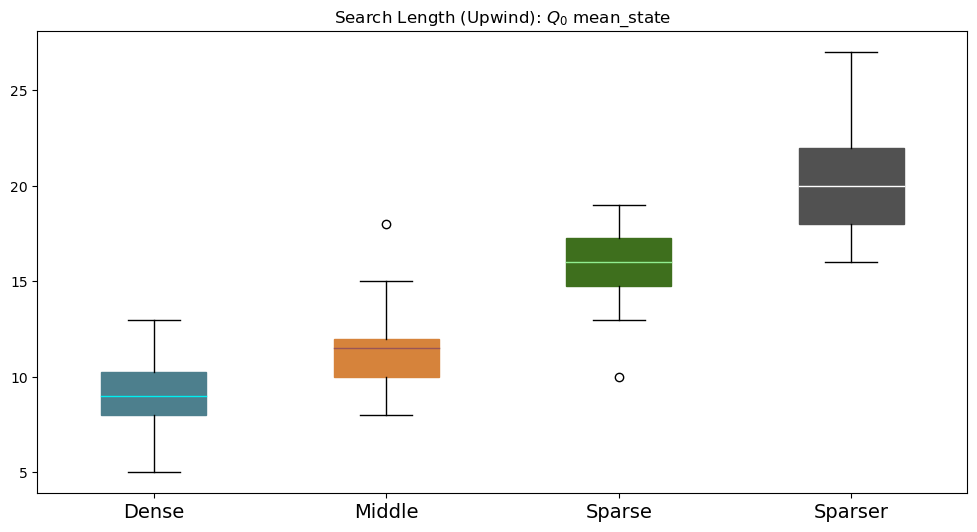

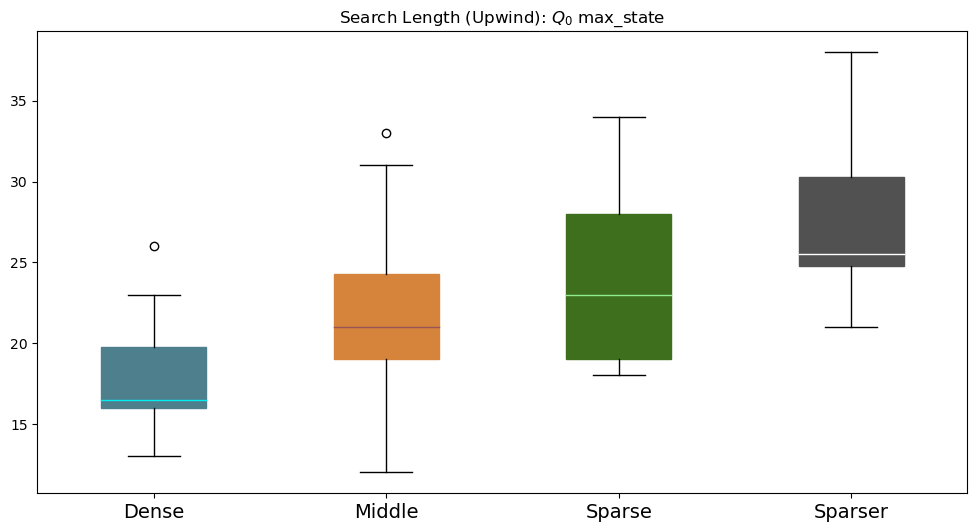

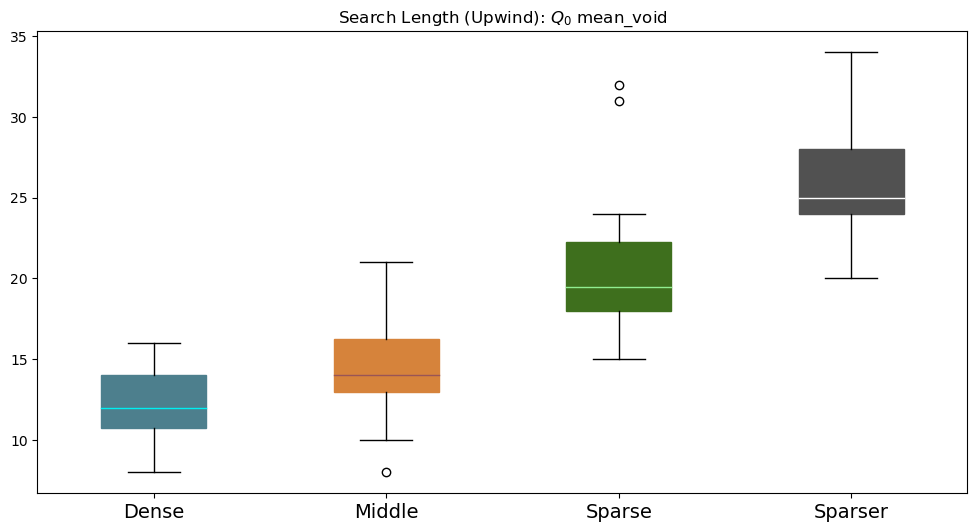

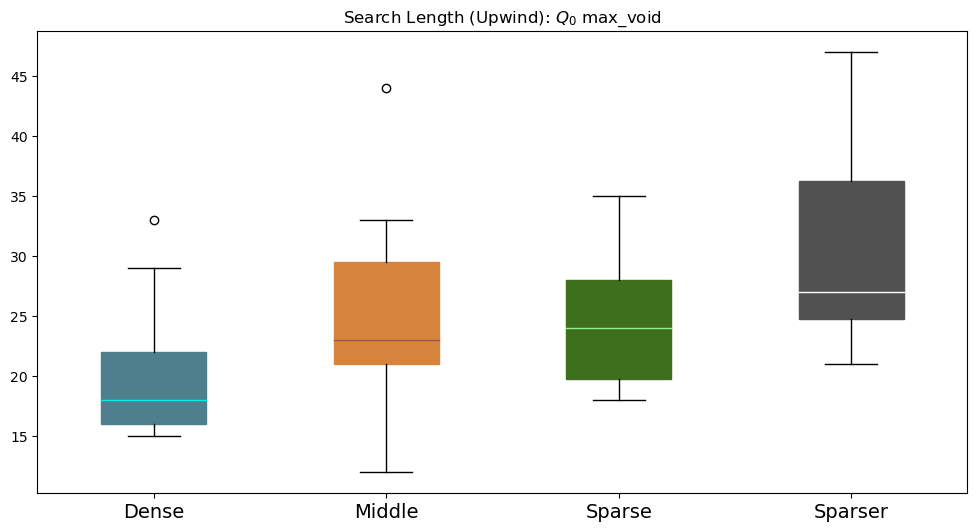

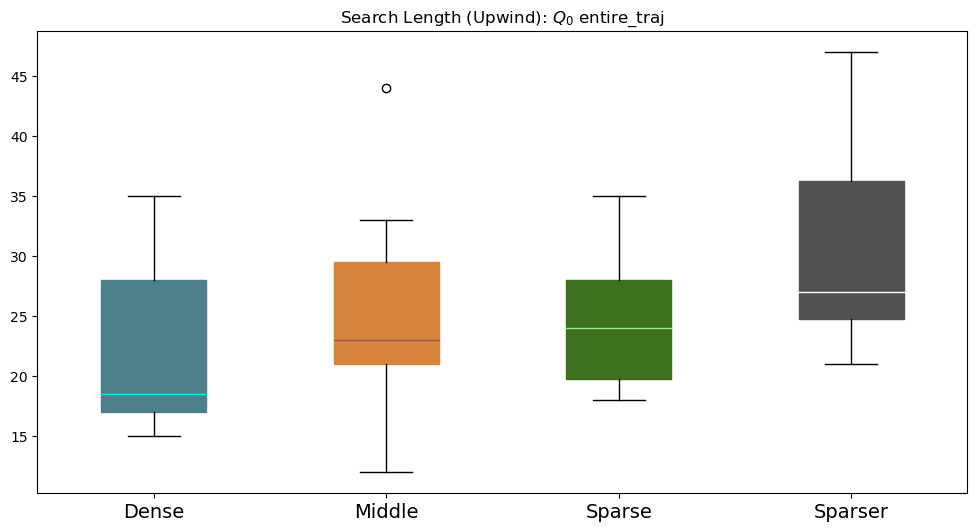

In [44]:

for met,met_name in zip(metrics, metric_names):

	search_len = [[], [], [], []]
	for (i, setting) in enumerate(settings):
			for (j, seed) in enumerate(agent_seeds):
					if met_name == 'entire_traj':
						search_len[i].append(compute_search_length(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/Q_stored/Qfun.npy", 502, count_from=0 ) ) 
					else:
						search_len[i].append(compute_search_length(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/Q_stored/Qfun.npy", round(met[i][j]), count_from=0 ) ) 


	fig, ax = plt.subplots(1, 1, figsize=(12, 6))

	b = ax.boxplot(search_len, patch_artist=True)
	for i in range(len(b['boxes'])):
			b['boxes'][i].set_color(box_colors[i])
			b['medians'][i].set_color(median_colors[i])

	ax.set_title(f"Search Length (Upwind): $Q_0$ {met_name}")
	ax.set_xticklabels(data_labels, fontsize=14)

#	fig.savefig(f"{out_path}/fig2_c_{met_name}.pdf", bbox_inches='tight')



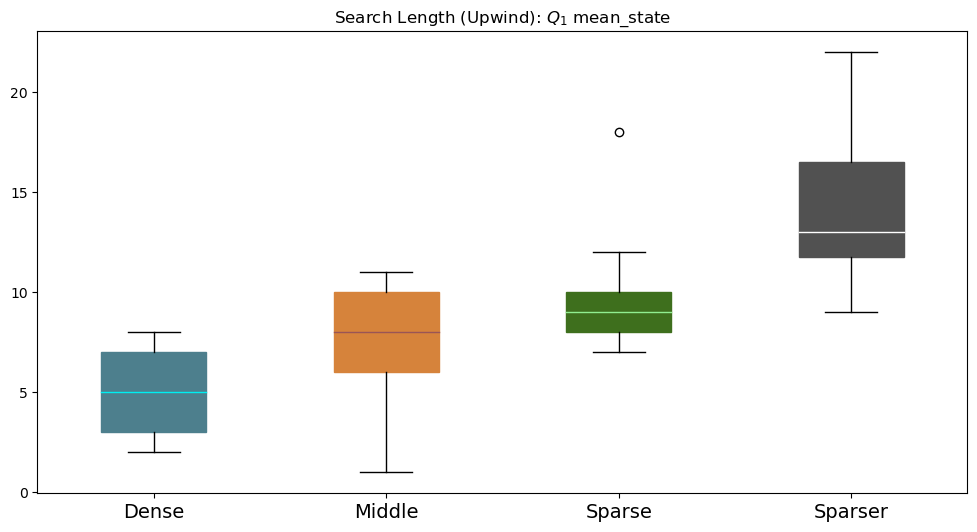

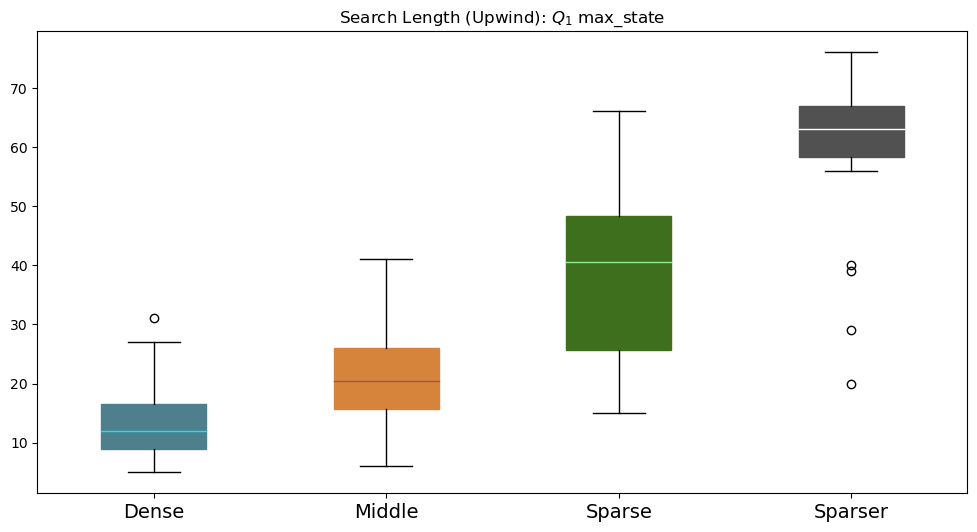

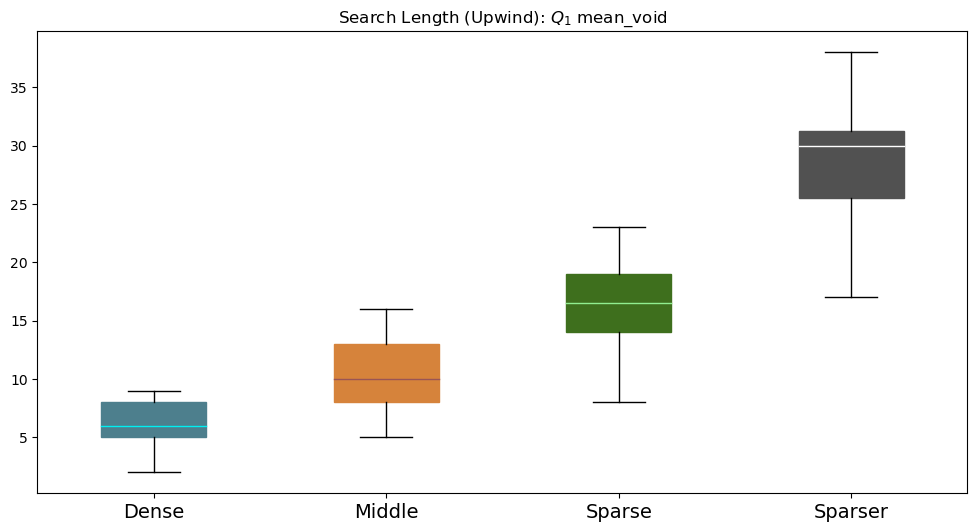

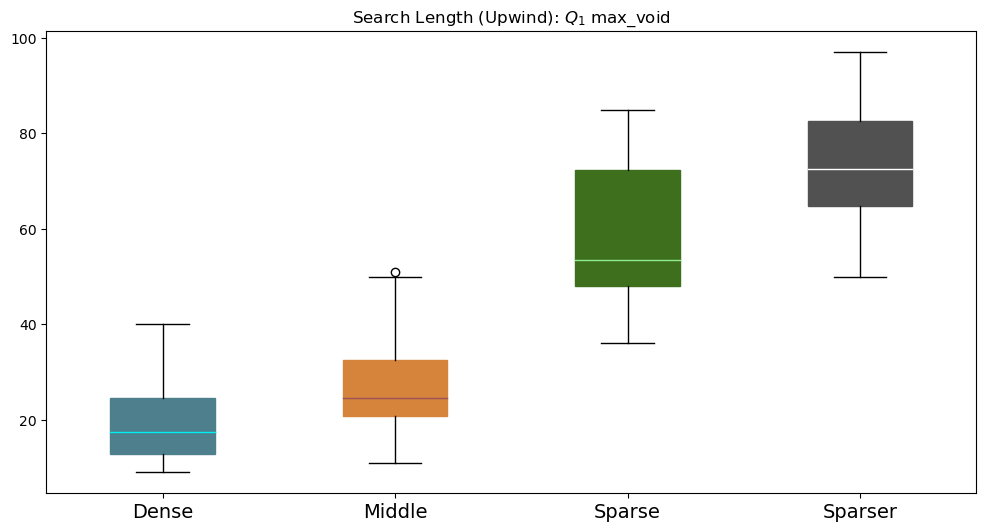

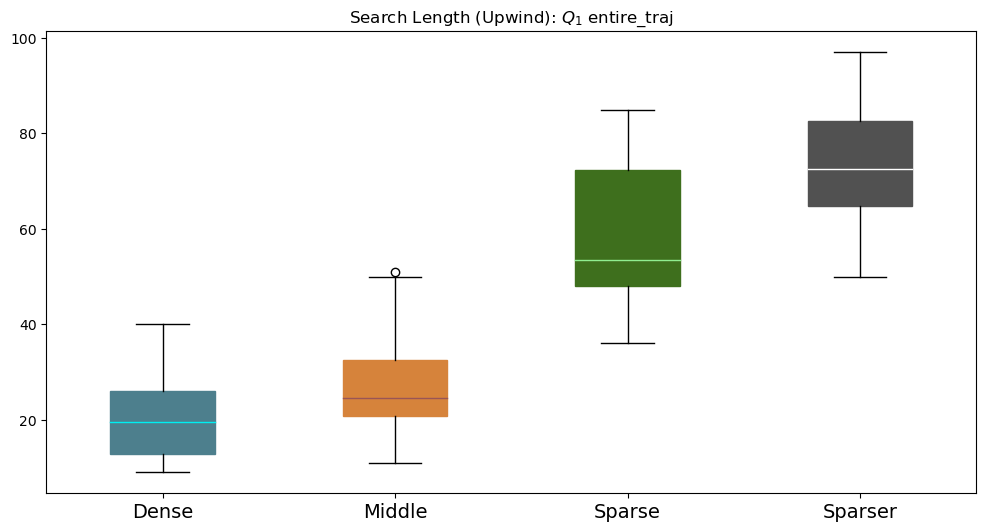

In [47]:

for met,met_name in zip(metrics, metric_names):

	search_len = [[], [], [], []]
	for (i, setting) in enumerate(settings):
			for (j, seed) in enumerate(agent_seeds):
					if met_name == 'entire_traj':
						search_len[i].append(compute_search_length(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/Q_stored/Qfun.npy", 1003, count_from=502 ) ) 
					else:
						search_len[i].append(compute_search_length(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/Q_stored/Qfun.npy", round(met[i][j]) + 502, count_from=502 ) ) 


	fig, ax = plt.subplots(1, 1, figsize=(12, 6))

	b = ax.boxplot(search_len, patch_artist=True)
	for i in range(len(b['boxes'])):
			b['boxes'][i].set_color(box_colors[i])
			b['medians'][i].set_color(median_colors[i])

	ax.set_title(f"Search Length (Upwind): $Q_1$ {met_name}")
	ax.set_xticklabels(data_labels, fontsize=14)

#	fig.savefig(f"{out_path}/fig2_c_{met_name}.pdf", bbox_inches='tight')



## Cast-Width

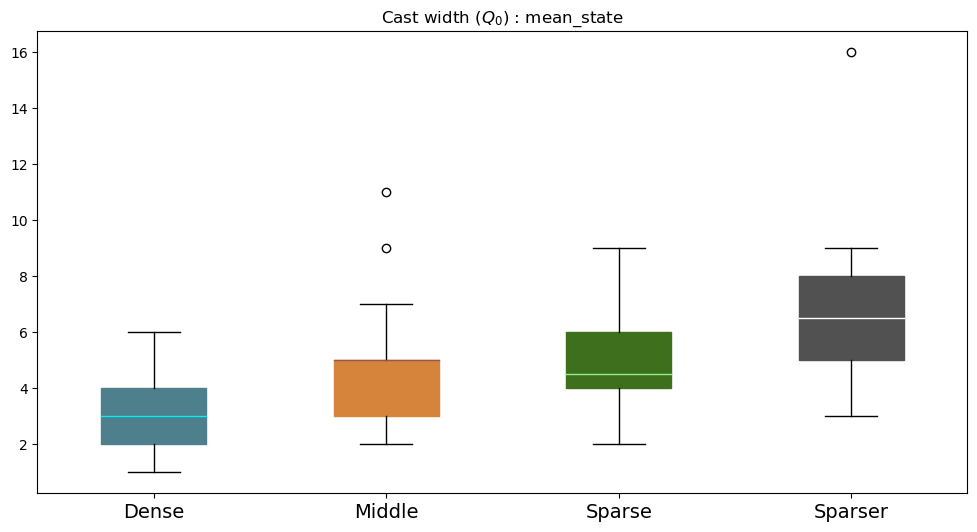

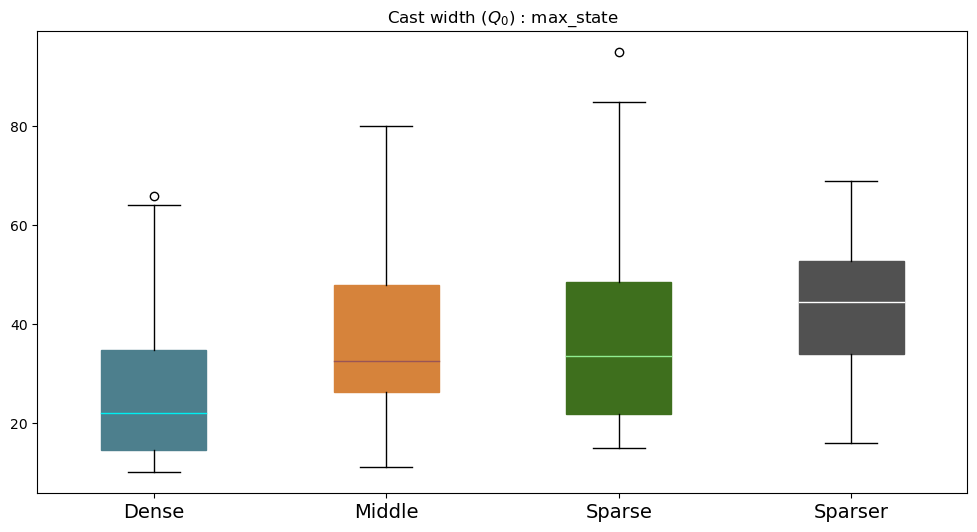

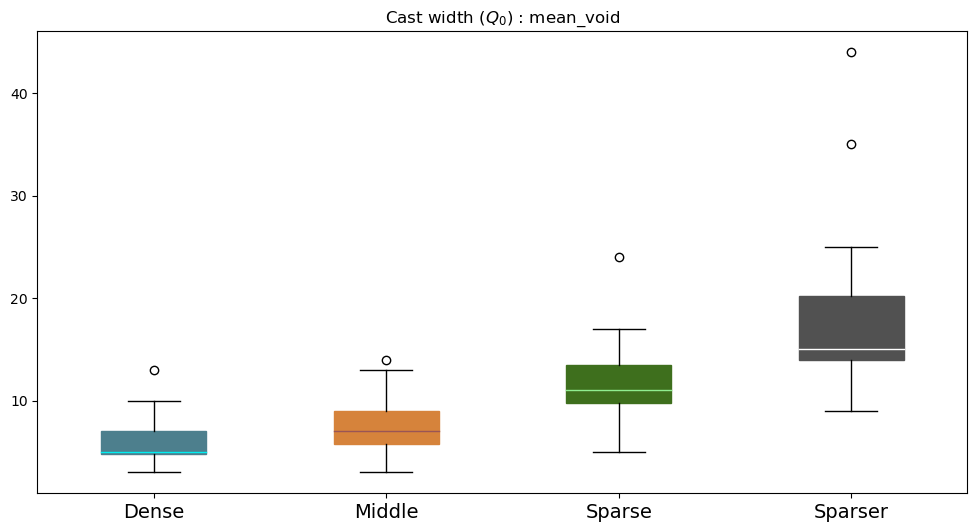

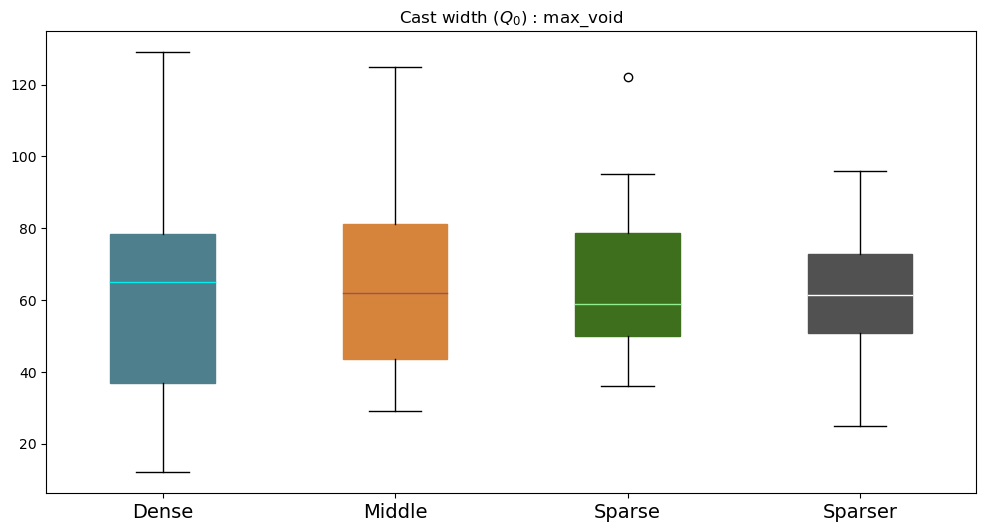

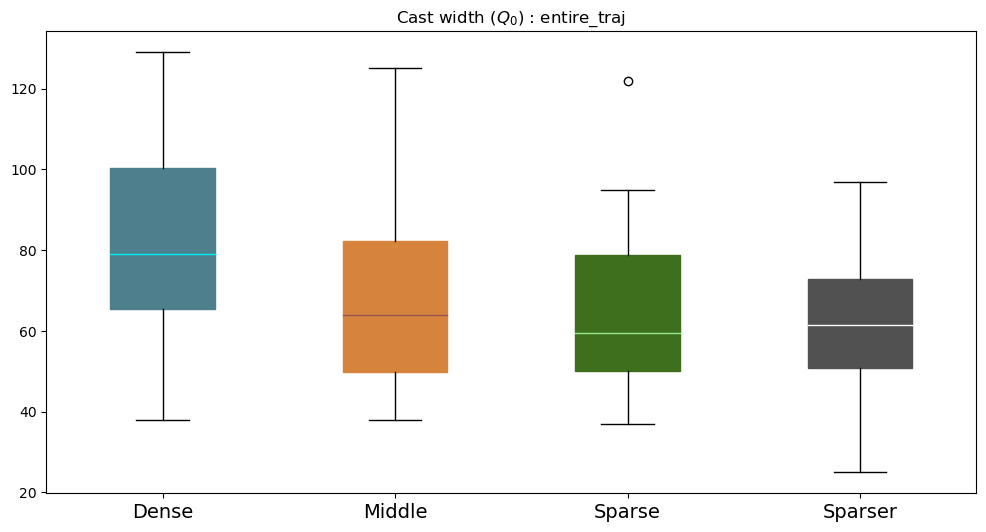

In [48]:



for met,met_name in zip(metrics, metric_names):
	cast_width = [[], [], [], []]

	for (i, setting) in enumerate(settings):
		for (j, seed) in enumerate(agent_seeds):
						if met_name == 'entire_traj':
							cast_width[i].append(compute_cast_width(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/Q_stored/Qfun.npy", 502, count_from=0) ) 
						else:
							cast_width[i].append(compute_cast_width(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/Q_stored/Qfun.npy", round(met[i][j]), count_from=0 ) ) 



	fig, ax = plt.subplots(1, 1, figsize=(12, 6))

	b = ax.boxplot(cast_width, patch_artist=True)

	for i in range(len(b['boxes'])):
		b['boxes'][i].set_color(box_colors[i])
		b['medians'][i].set_color(median_colors[i])


	ax.set_title(f"Cast width ($Q_0$) : {met_name}")
	ax.set_xticklabels(data_labels, fontsize=14)
#	fig.savefig(f"{out_path}/fig2_d_{met_name}.pdf", bbox_inches='tight')
			




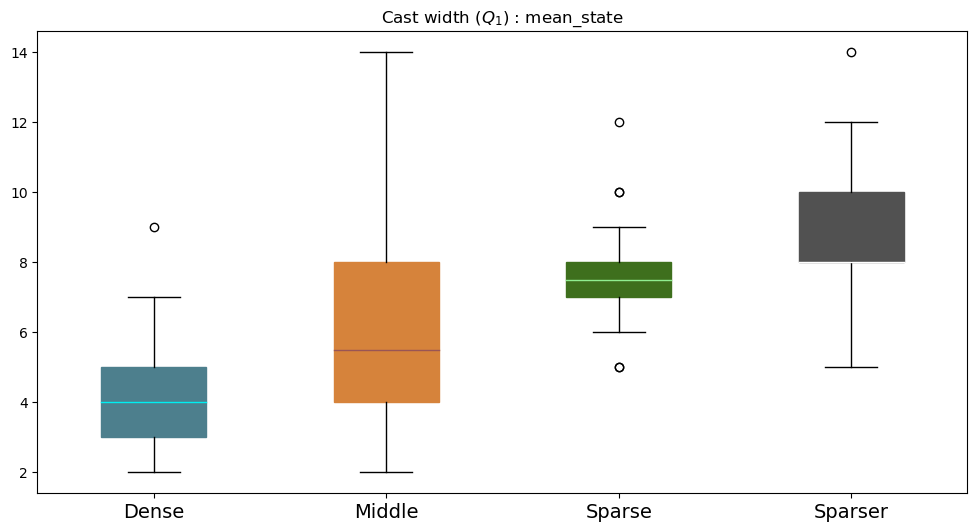

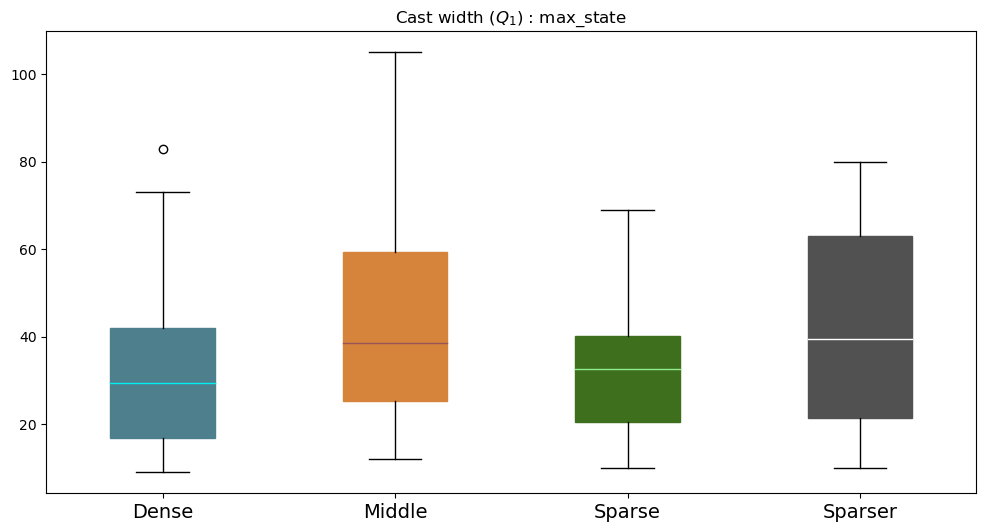

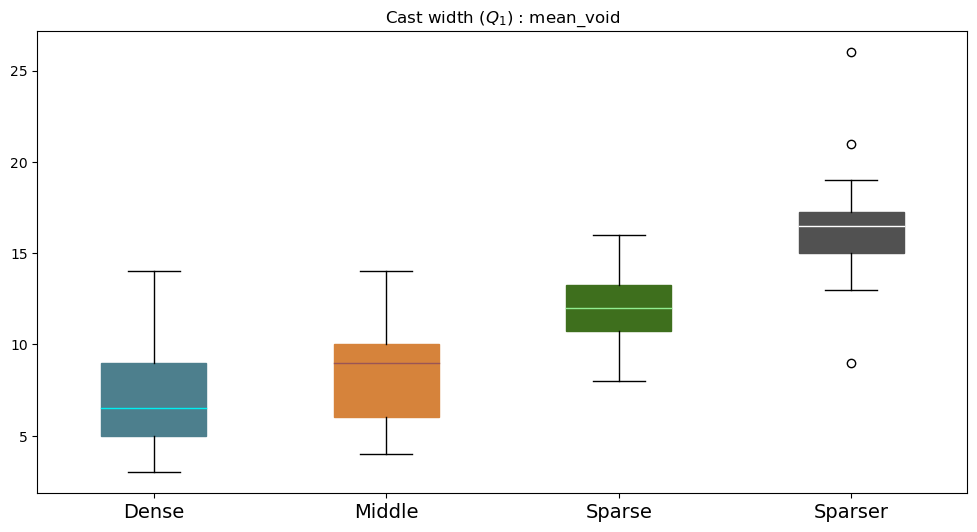

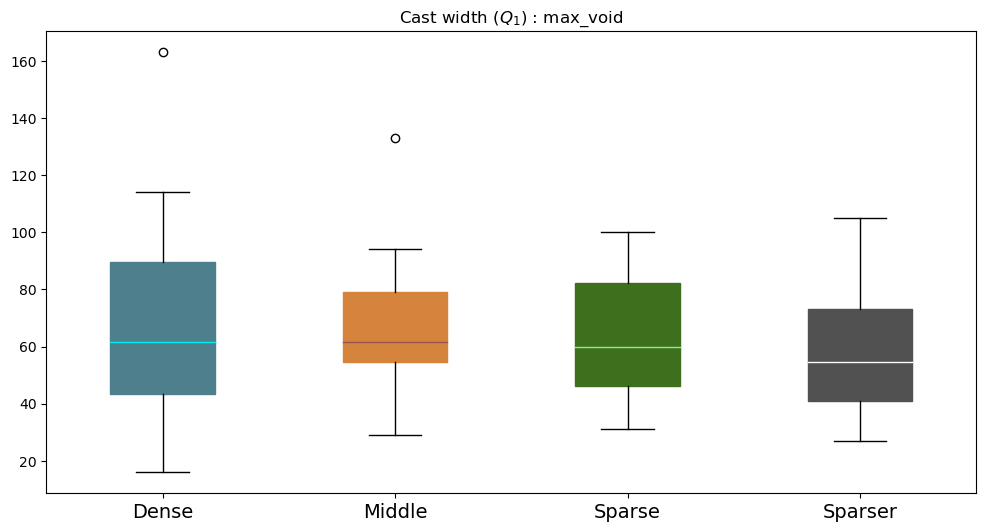

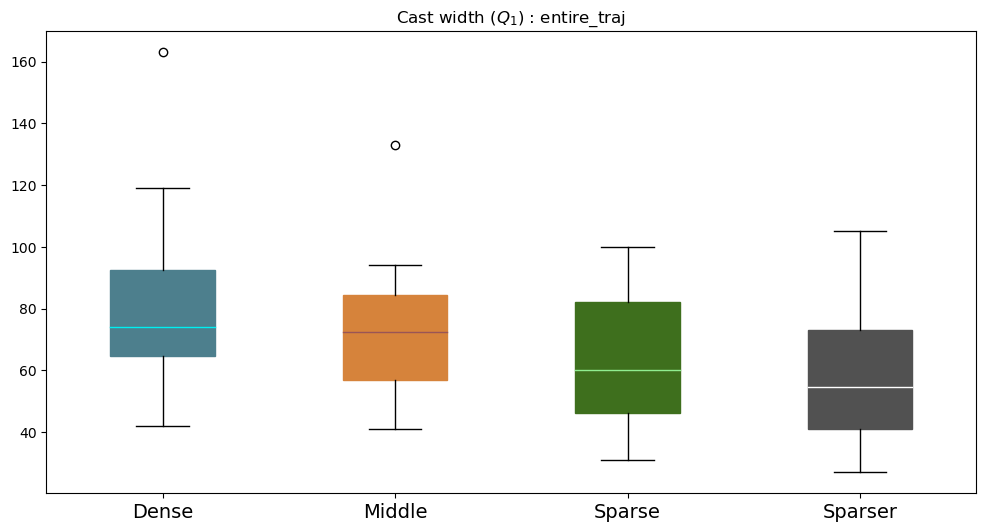

In [50]:



for met,met_name in zip(metrics, metric_names):
	cast_width = [[], [], [], []]

	for (i, setting) in enumerate(settings):
		for (j, seed) in enumerate(agent_seeds):
						if met_name == 'entire_traj':
							cast_width[i].append(compute_cast_width(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/Q_stored/Qfun.npy", 1003, count_from=502) ) 
						else:
							cast_width[i].append(compute_cast_width(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/Q_stored/Qfun.npy", round(met[i][j]) + 502, count_from=502 ) ) 



	fig, ax = plt.subplots(1, 1, figsize=(12, 6))

	b = ax.boxplot(cast_width, patch_artist=True)

	for i in range(len(b['boxes'])):
		b['boxes'][i].set_color(box_colors[i])
		b['medians'][i].set_color(median_colors[i])


	ax.set_title(f"Cast width ($Q_1$) : {met_name}")
	ax.set_xticklabels(data_labels, fontsize=14)
#	fig.savefig(f"{out_path}/fig2_d_{met_name}.pdf", bbox_inches='tight')
			




## Backtracking Length

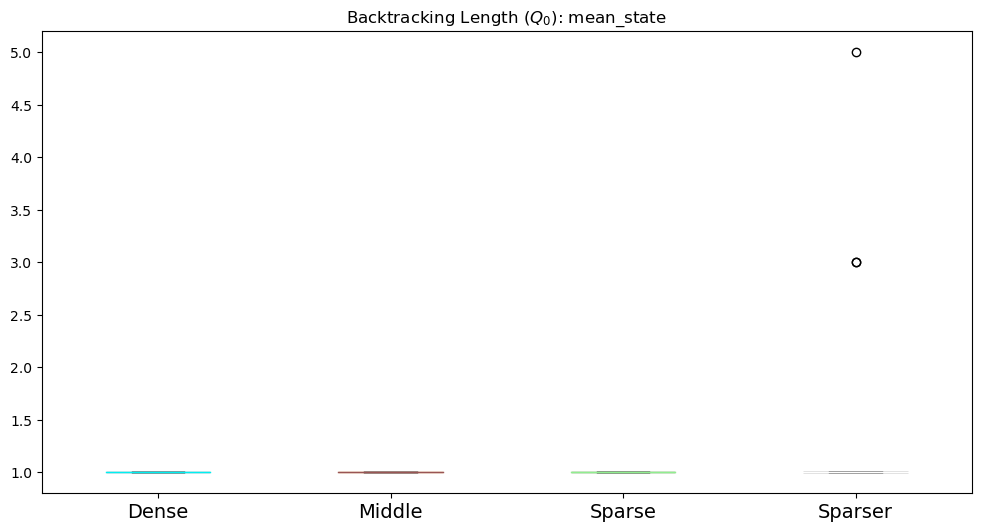

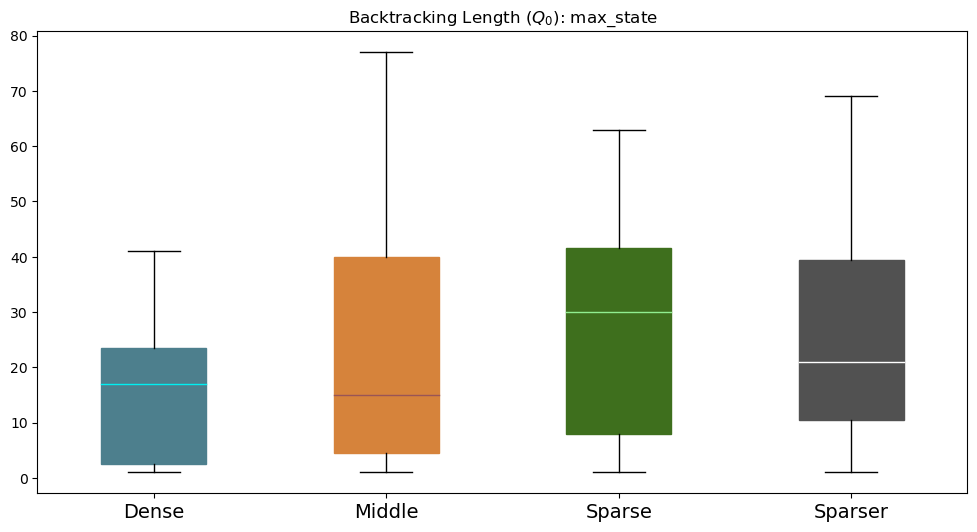

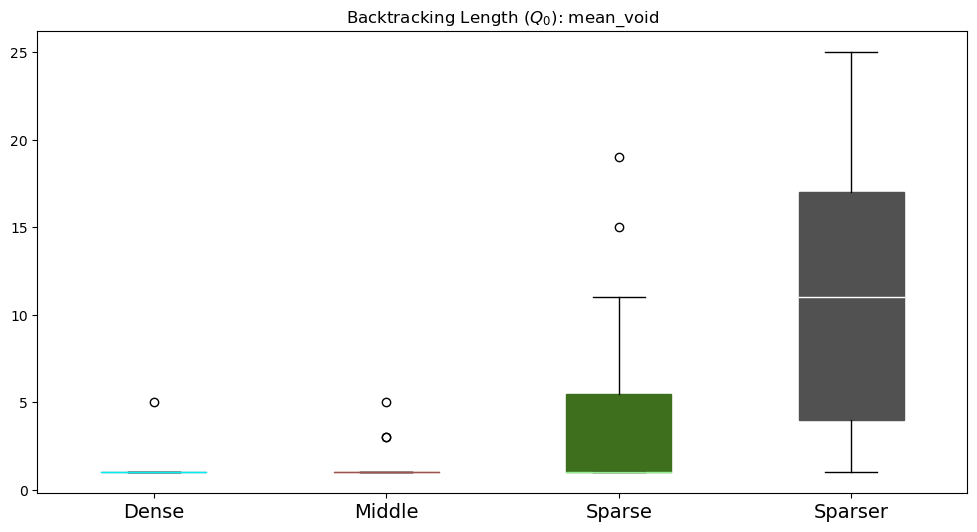

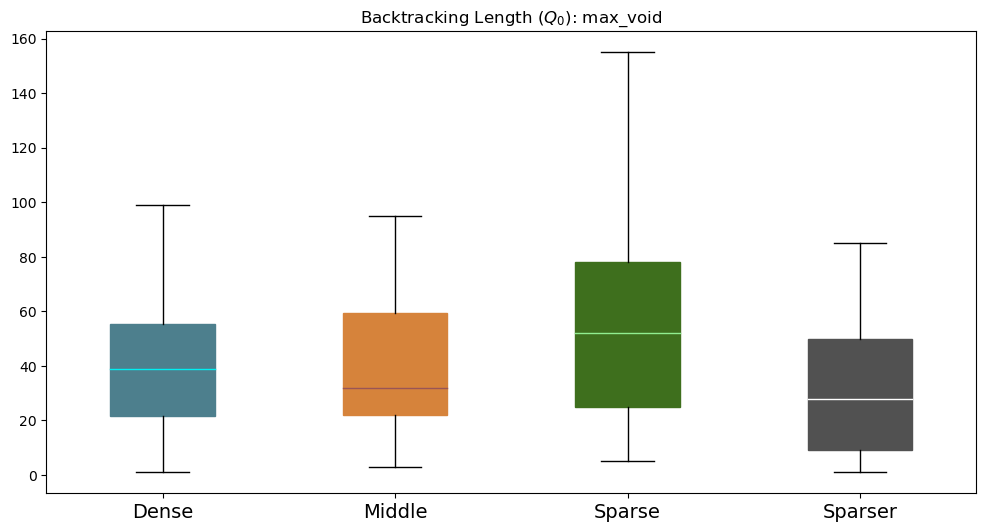

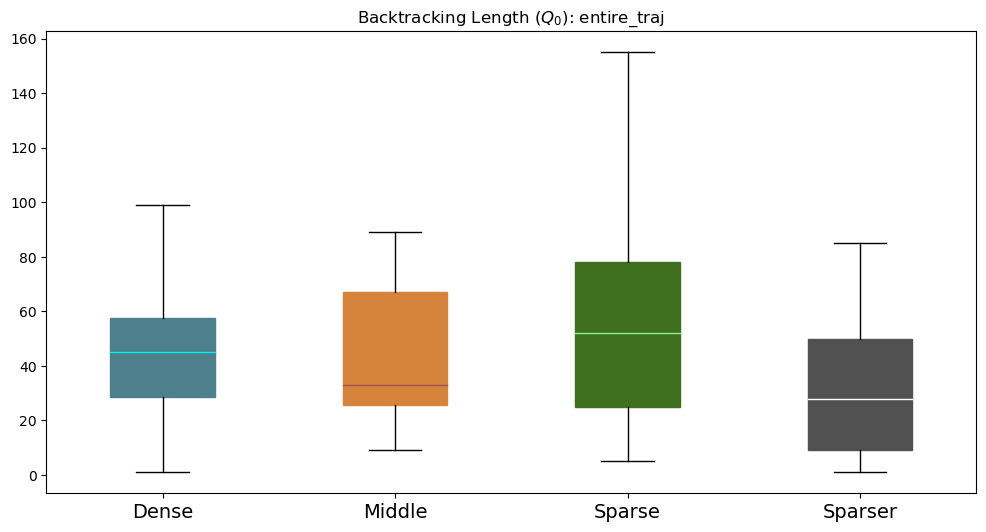

In [52]:

for met,met_name in zip(metrics, metric_names):

	bck_len = [[], [], [], []]

	for (i, setting) in enumerate(settings):
			for (j, seed) in enumerate(agent_seeds):
					if met_name == 'entire_traj':
						bck_len[i].append(compute_backtracking_length(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/Q_stored/Qfun.npy", 502, count_from=0 ) ) 
					else:
						bck_len[i].append(compute_backtracking_length(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/Q_stored/Qfun.npy", round(met[i][j]), count_from=0 ) ) 


	fig, ax = plt.subplots(1, 1, figsize=(12, 6))

	b = ax.boxplot(bck_len, patch_artist=True)
	for i in range(len(b['boxes'])):
			b['boxes'][i].set_color(box_colors[i])
			b['medians'][i].set_color(median_colors[i])

	ax.set_title(f"Backtracking Length ($Q_0$): {met_name}")
	ax.set_xticklabels(data_labels, fontsize=14)
#	fig.savefig(f"{out_path}/fig2_e_{met_name}.pdf", bbox_inches='tight')
#	plt.close(fig)



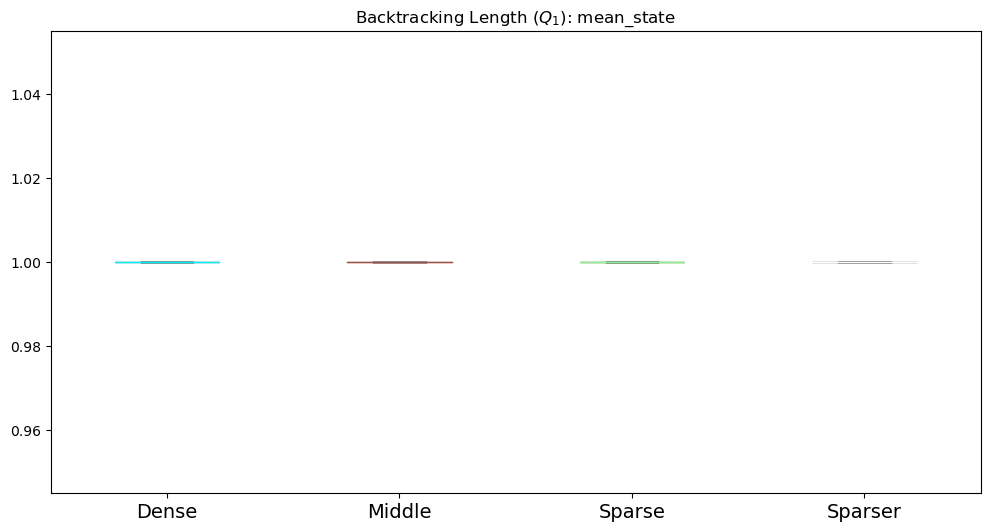

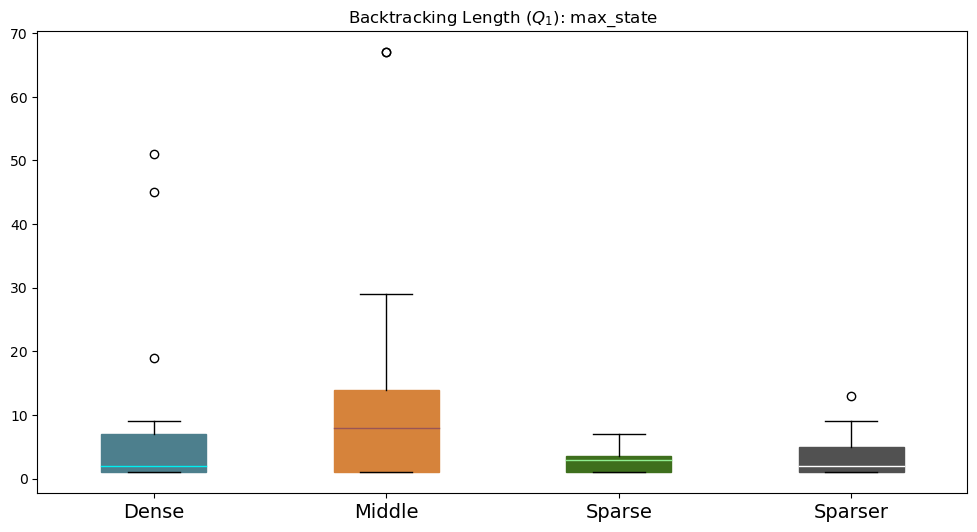

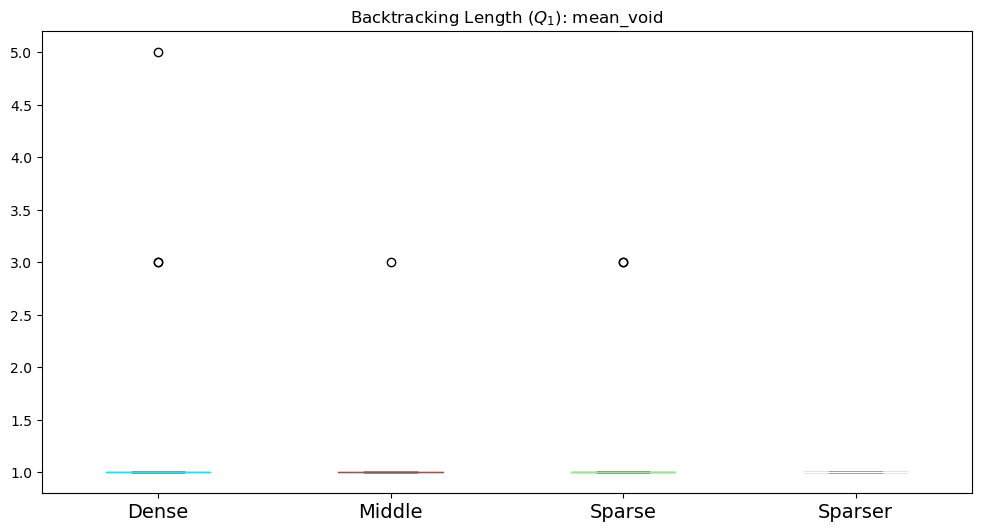

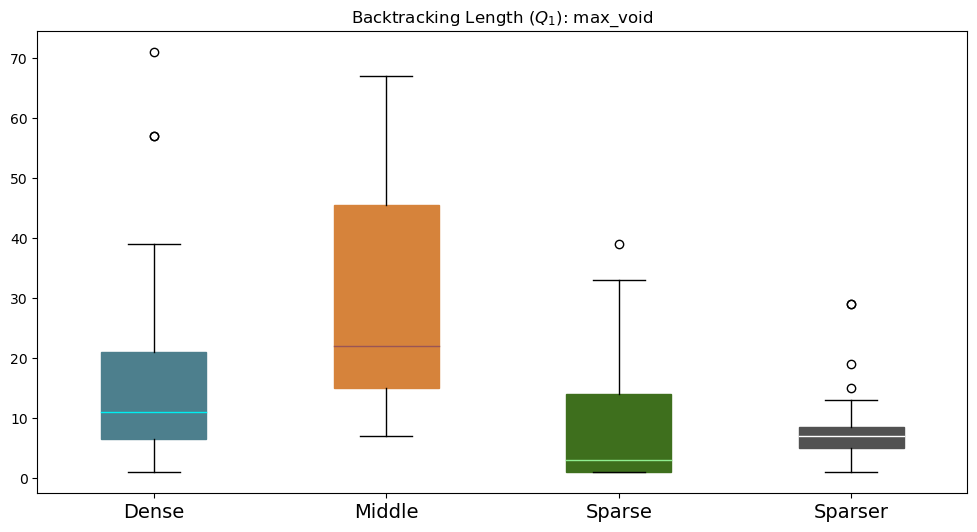

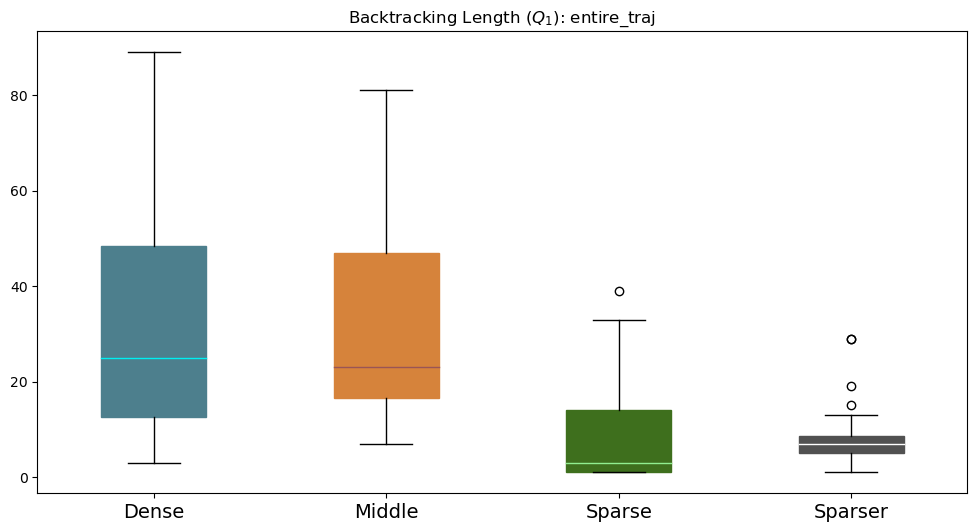

In [53]:

for met,met_name in zip(metrics, metric_names):

	bck_len = [[], [], [], []]

	for (i, setting) in enumerate(settings):
			for (j, seed) in enumerate(agent_seeds):
					if met_name == 'entire_traj':
						bck_len[i].append(compute_backtracking_length(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/Q_stored/Qfun.npy", 1003, count_from=502 ) ) 
					else:
						bck_len[i].append(compute_backtracking_length(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/Q_stored/Qfun.npy", round(met[i][j]) + 502, count_from=502) ) 


	fig, ax = plt.subplots(1, 1, figsize=(12, 6))

	b = ax.boxplot(bck_len, patch_artist=True)
	for i in range(len(b['boxes'])):
			b['boxes'][i].set_color(box_colors[i])
			b['medians'][i].set_color(median_colors[i])

	ax.set_title(f"Backtracking Length ($Q_1$): {met_name}")
	ax.set_xticklabels(data_labels, fontsize=14)
#	fig.savefig(f"{out_path}/fig2_e_{met_name}.pdf", bbox_inches='tight')
#	plt.close(fig)



## Backtracking Init Time

[Text(1, 0, 'Dense'),
 Text(2, 0, 'Middle'),
 Text(3, 0, 'Sparse'),
 Text(4, 0, 'Sparser')]

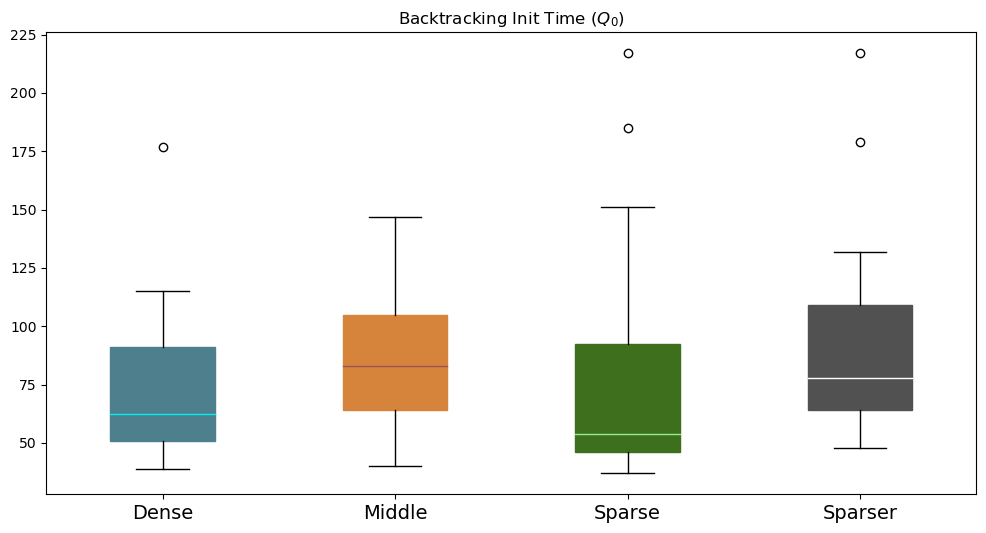

In [54]:



backtrack_init = [[], [], [], []]
acc_steps = 3
for (i, setting) in enumerate(settings):
    for (j, seed) in enumerate(agent_seeds):

        # entire trajectory
        backtrack_init[i].append(compute_backtracking_init_time(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/Q_stored/Qfun.npy", 502, acc_steps ))


fig, ax = plt.subplots(1, 1, figsize=(12, 6))

b = ax.boxplot(backtrack_init, patch_artist=True)
for i in range(len(b['boxes'])):
    b['boxes'][i].set_color(box_colors[i])
    b['medians'][i].set_color(median_colors[i])

ax.set_title("Backtracking Init Time ($Q_0$)")

ax.set_xticklabels(data_labels, fontsize=14)
#fig.savefig(f"{out_path}/fig2_f.pdf", bbox_inches='tight')
#plt.close(fig)


[Text(1, 0, 'Dense'),
 Text(2, 0, 'Middle'),
 Text(3, 0, 'Sparse'),
 Text(4, 0, 'Sparser')]

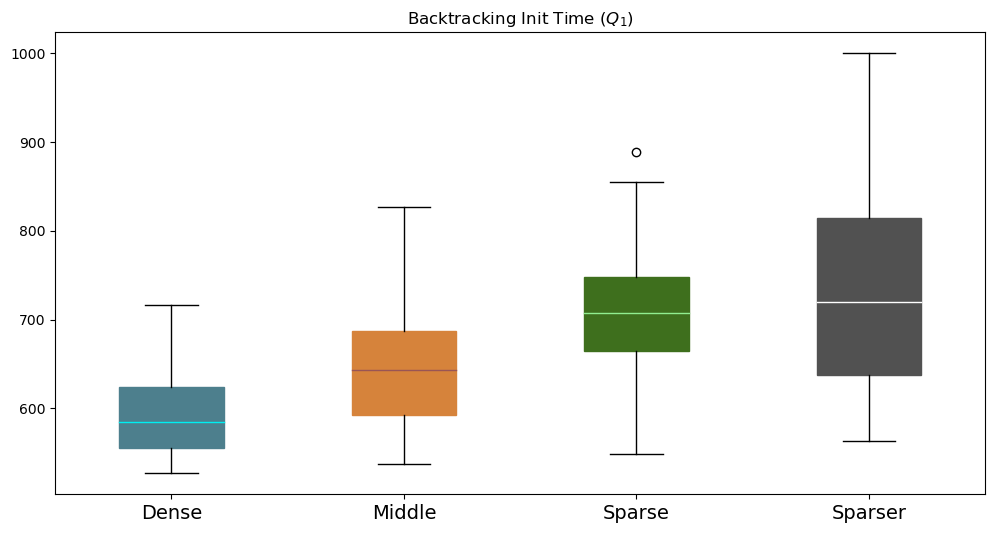

In [56]:



backtrack_init = [[], [], [], []]
acc_steps = 3
for (i, setting) in enumerate(settings):
    for (j, seed) in enumerate(agent_seeds):

        # entire trajectory
        backtrack_init[i].append(compute_backtracking_init_time(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/Q_stored/Qfun.npy", 1003, acc_steps, count_from=502 ))


fig, ax = plt.subplots(1, 1, figsize=(12, 6))

b = ax.boxplot(backtrack_init, patch_artist=True)
for i in range(len(b['boxes'])):
    b['boxes'][i].set_color(box_colors[i])
    b['medians'][i].set_color(median_colors[i])

ax.set_title("Backtracking Init Time ($Q_1$)")

ax.set_xticklabels(data_labels, fontsize=14)
#fig.savefig(f"{out_path}/fig2_f.pdf", bbox_inches='tight')
#plt.close(fig)
